# Optimal Wormhole Geometries

### Problem Statement:
- The speed of light is the upper limit at which objects (with non-negative mass) can travel through space. It is dwarfed by the scale of the universe; with current rocket technology, it would take ~80,000 years to reach our nearest star. If traveling outside our solar system will ever be feasible, we will need to explore alternatives.
- Wormholes are a geometric structure of spacetime, hyperbolically curved such that they connect two distant regions. This hyperbolic curvature requires gravity to repel rather than attract; a property of negative mass (exotic matter). As such, none are theorized to exist in our universe. The goal of this project is to investigate whether a Physics-Informed Neural Network (PINN) can identify wormhole geometries that satisfy physical requirements, while minimizing the amount of exotic matter required. Using its numerical predictions, an analytical form can be derived via Symbolic (or Linear) Regression. The feasibility of experimentally creating this optimal geometry is evaluated by optimizing the quantum field, generated experimentally via the Casimir effect.
- The neural network - symbolic regression pipeline generates two equations: the wormhole shape $b(r)$ and redshift derivative $\chi'(r)$.
    - $b(r)$ describes the geometric shape (where 'r' is the radial distance to the 'throat' - the smallest point)
    - $\chi'(r)$ describes the tidal forces (must be low to avoid being crushed or stretched upon traversal).
        - In ML terms, this is a regularization constant. A high $\chi'(r)$ value presents a steep gradient.
<br></br>
- To be stable and traversable, a wormhole must satisfy the following conditions:
    - L_GEOM_R0 (Throat Constraint): Forces the shape function $b(r)$ to equal the throat radius $r_0$ at the origin, providing a stable entrance.
    - L_GEOM_R (Flaring-Out Condition): Penalizes any cases of $b(r) \ge r$. Enforces the requirement that the wormhole must flare out to connect two distant regions of spacetime.
    - L_CHI_INF (Asymptotic Flatness): Ensures that the gravitational tidal forces ($\chi'$) disappear at large distances. This ensures the wormhole connects to flat space.
    - L_PR (Radial Tension): Enforces that the radial pressure $P_r \le 0$ (tension), preventing the wormhole from flying apart.
    - L_NEC_R & L_NEC_T (Null Energy Conditions): These are the exotic matter requirements ($\rho + P$). Minimizing the residual, the model finds the negative energy needed to hold the throat open against gravitational collapse.
    - L_CAUS (Causality/Scalar Field Constraint): Ensures the solution remains non-imaginary (prevents exceeding the speed of light).
<br></br>
- Success is measured by the neural network and symbolic $R^2$ scores, and the physical validity boolean (satisfying 7 the general relativity constraints).
- The feasibility is evaluated by comparing the negative energy of the optimized quantum field to the wormhole's requirements.
- NOTE: All optimization / trainings use a reduced number of trials and points for faster review.
    - All calculations use the best equations found, using much higher number of iterations.

### Why Deep Learning?
- Standard numerical optimizers often fail or diverge when faced with the multi-modal objectives and constraints of a wormhole.
- Deep Learning (PINNs) treats this as an optimization problem, allowing the model to generate numerous weights to explore the geometry much more flexibly than traditional machine learning or statistical models.
    - This scales well with increasing complexity, if more constraints are added.
- We can utilize its predictions to generate a dataset, to then fit a symbolic regression.

### Approach:
- Part 1 (Neural Network - Symbolic Regression):
    - Genetic algorithm finds the optimal throat radius and neural network training hyperparameters, via the hyperparameter objective function.
    - Train neural network on 'r' input coordinates using the physics loss function to create models for shape function $b(r)$ and redshift derivative $\chi'(r)$.
    - Generate a dataset of model predictions using various 'r' coordinates.
    - Symbolic regression is fit to this dataset to derive analytical equation forms for $b(r)$, $\chi'(r)$.
        - This is run multiple times to generate several equation forms.
    - Iterate over permutations of resulting $b(r)$ and $\chi'(r)$ equation forms to find the best combination.
    - Linear regression serves as a baseline model for comparison to symbolic regression.
####
- Part 2 (Evolutionary Optimization)
- 2a. (Optimize Best Equation):
    - The coefficients of the best equations are optimized.
- 2b. (Optimize Quantum Field):
    - Trace amounts of negative energy have been created experimentally via the Casimir effect. Can this support our wormhole equations?
        - Objective function is defined for Casimir energy generation, respective to optimal wormhole dimensions
        - Optimize the parameters to maximize total negative energy.
        - Analyze how much improvement would be needed to support our wormhole.

## Imports & Helpers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdim_opt
import warnings
import os

from scipy.integrate import odeint
from scipy.optimize import approx_fprime
import optuna
import torch
import torch.nn as nn
import torch.optim as optim
import itertools
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sympy import symbols, sympify, Function
from sympy import symbols, sympify, diff, Function, lambdify
from sympy.printing.str import StrPrinter
from sympy.printing.latex import LatexPrinter
from sympy.printing.str import StrPrinter
from sympy.printing.latex import LatexPrinter
from gplearn.functions import _Function
from gplearn.genetic import SymbolicRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.utils.validation import check_X_y, check_array
from typing import List, Dict, Any, Tuple
plt.style.use('dark_background')
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns',None)

# define neural network model
class WormholeNet(nn.Module):
    # R_END is passed upon instantiation
    def __init__(self, n_hidden=64, n_layers=5, R_END=50.0):
        super(WormholeNet, self).__init__()
        # R_END is tensor for normalization
        self.R_END_tensor = torch.tensor(R_END, dtype=torch.float32)
        self.trunk = nn.Sequential(nn.Linear(1, n_hidden), nn.Tanh(),)
        for _ in range(n_layers - 1):
            self.trunk.add_module(f'hidden_{_}', nn.Linear(n_hidden, n_hidden))
            self.trunk.add_module(f'activation_{_}', nn.Tanh())
        self.output_b = nn.Linear(n_hidden, 1) 
        self.output_chi_prime = nn.Linear(n_hidden, 1)

    def forward(self, r):
        # normalize using R_END specific to this trial
        r_normalized = r / self.R_END_tensor
        r_processed = self.trunk(r_normalized)
        b_r_output = self.output_b(r_processed)
        chi_prime_output = self.output_chi_prime(r_processed)
        return b_r_output, chi_prime_output

def physics_informed_loss(r_vals, r0_val, model, C_weights):
    '''Neural network loss function.'''
    # neural network outputs
    b_r, chi_prime_r = model(r_vals)
    b_prime_r = torch.autograd.grad(b_r, r_vals, grad_outputs=torch.ones_like(b_r), create_graph=True)[0]
    chi_prime_prime_r = torch.autograd.grad(chi_prime_r, r_vals, grad_outputs=torch.ones_like(chi_prime_r), create_graph=True)[0]

    # physical metrics
    r_sq, r_cube = r_vals**2, r_vals**3
    f_r = 1.0 - b_r / r_vals
    rho_geom = (r_vals * b_prime_r - b_r) / r_cube
    pr_geom = -rho_geom - 2 * f_r * (chi_prime_r / r_vals)
    G_theta_theta = (1/r_sq) * (0.5 * (r_vals * b_prime_r - b_r) + (r_vals - b_r) * (r_vals * chi_prime_prime_r + chi_prime_r) + 0.5 * r_vals * b_prime_r * chi_prime_r)
    pt_geom = G_theta_theta
    
    ### L1 energy loss
    negative_rho_mask = (rho_geom < 0).float()
    volume_factor_geom = r_sq / torch.sqrt(torch.clamp(f_r, min=1e-8))
    L_EXOTIC = torch.sum(torch.abs(rho_geom) * negative_rho_mask * volume_factor_geom)
    weighted_L_EXOTIC = C_weights['C_NEGATIVE_RHO_COST'] * L_EXOTIC
    
    ### general relativity constraints
    L_PR = torch.mean(torch.relu(pr_geom)**2)
    L_NEC_R = torch.mean(torch.relu(rho_geom + pr_geom)**2)
    L_NEC_T = torch.mean(torch.relu(rho_geom + pt_geom)**2)
    L_GEOM_R = torch.mean(torch.relu(b_r - r_vals)**2)
    L_GEOM_R0 = (b_r[0] - r0_val)**2
    L_CAUS = torch.mean(torch.relu(- (rho_geom - pr_geom) / torch.clamp(f_r, min=1e-6) )**2)
    L_CHI_INF = chi_prime_r[-1]**2
    L_L2 = sum(torch.norm(param, p=2) for param in model.parameters())

    ### total loss (weighted)
    total_loss = (
        weighted_L_EXOTIC +
        C_weights['C_RADIAL_PRESSURE'] * L_PR +       
        C_weights['C_NEC_RADIAL'] * L_NEC_R +                                     
        C_weights['C_NEC_TANGENTIAL'] * L_NEC_T +                                  
        C_weights['C_GEOM_B_THROAT'] * L_GEOM_R0 +                                 
        C_weights['C_CAUSALITY'] * L_CAUS +                                        
        C_weights['C_GEOM_B_LESS_R'] * L_GEOM_R +
        C_weights['C_CHI_PRIME_INF'] * L_CHI_INF +
        1e-8 * L_L2 
    )

    ### diagnostic dictionary
    penalty_dict = {
        'Loss_Total': total_loss.item(),
        'L_EXOTIC': L_EXOTIC.item(), 
        'L_PR': L_PR.item(), 'L_NEC_R': L_NEC_R.item(), 'L_NEC_T': L_NEC_T.item(), 
        'L_GEOM_R': L_GEOM_R.item(), 'L_GEOM_R0': L_GEOM_R0.item(), 'L_CHI_INF': L_CHI_INF.item(),
        'L_CAUS': L_CAUS.item(), 'L_L2': L_L2.item(),
    }

    return total_loss, penalty_dict

### hyperparameter optimization via genetic algorithm
def hyperparameter_objective(trial):
    '''Objective function to minimize.'''
    
    R_THROAT_MAX = 100.0 # max throat radius
    R_THROAT = trial.suggest_loguniform('R_THROAT', 0.5, R_THROAT_MAX) 
    
    # sample R_END based on the sampled R_THROAT with buffer of 20 units for asymptotes
    R_END_MIN = R_THROAT + 20.0 
    R_END_MAX = 200.0 # search limit
    
    # ensure valid sampling range
    if R_END_MIN >= R_END_MAX:
        raise optuna.exceptions.TrialPruned("R_THROAT too close to R_END_MAX.")
    R_END = trial.suggest_uniform('R_END', R_END_MIN, R_END_MAX)   

    # sample grid (with buffer)
    BUFFER_SIZE = trial.suggest_int('BUFFER_SIZE', 1, 20)

    # construct geometric tensors
    r_vals_np = np.linspace(R_THROAT + 1e-4, R_END, n_points, dtype=np.float32)
    r_vals_interior = r_vals_np[BUFFER_SIZE:-BUFFER_SIZE]

    # ensure valid length
    if len(r_vals_interior) < 50: 
        raise optuna.exceptions.TrialPruned("Buffer size too large for n_points.")
        
    r_vals_tensor = torch.tensor(r_vals_interior, requires_grad=True).unsqueeze(-1)
    r0_tensor = torch.tensor(R_THROAT, dtype=torch.float32)

    # sample the penalty coefficients
    penalty_dict_C = {
        'C_NEGATIVE_RHO_COST': trial.suggest_loguniform('C_NEGATIVE_RHO_COST', 1e0, 1e3),
        'C_RADIAL_PRESSURE': trial.suggest_loguniform('C_RADIAL_PRESSURE', 1e1, 1e5),
        'C_NEC_RADIAL': trial.suggest_loguniform('C_NEC_RADIAL', 1e1, 1e5),
        'C_NEC_TANGENTIAL': trial.suggest_loguniform('C_NEC_TANGENTIAL', 1e1, 1e5),
        'C_GEOM_B_THROAT': trial.suggest_loguniform('C_GEOM_B_THROAT', 1e2, 1e6),
        'C_GEOM_B_LESS_R': trial.suggest_loguniform('C_GEOM_B_LESS_R', 1e0, 1e3),
        'C_CAUSALITY': trial.suggest_loguniform('C_CAUSALITY', 1e0, 1e3),
        'C_CHI_PRIME_INF': trial.suggest_loguniform('C_CHI_PRIME_INF', 1e-3, 1e1) 
    }

    ### optimize learning rate
    learning_rate = trial.suggest_loguniform('lr', 1e-6, 5e-5)

    # instantiate model and optimizer
    model = WormholeNet(n_hidden=64, n_layers=5, R_END=R_END)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    ### training loop
    for epoch in range(10000):
        optimizer.zero_grad()
        total_loss, penalty_dict_L = physics_informed_loss(r_vals_tensor, r0_tensor, model, penalty_dict_C)
        total_loss.backward()
        optimizer.step()
        
        # pruning check
        if (epoch + 1) % 500 == 0:
            # objective score to measure violations
            current_constraint_violations = (
                penalty_dict_L['L_NEC_R'] + penalty_dict_L['L_NEC_T'] + penalty_dict_L['L_GEOM_R'] +
                penalty_dict_L['L_PR'] + penalty_dict_L['L_CAUS'] + penalty_dict_L['L_GEOM_R0'] + 
                penalty_dict_L['L_CHI_INF']
            )
            CONSTRAINT_MULTIPLIER = 1e4
            current_objective_score = (
                CONSTRAINT_MULTIPLIER * current_constraint_violations + penalty_dict_L['L_EXOTIC']
            )
            
            trial.report(current_objective_score, step=epoch)
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    # final objective function score
    constraint_violations = (
        penalty_dict_L['L_NEC_R'] + penalty_dict_L['L_NEC_T'] + penalty_dict_L['L_GEOM_R'] + 
        penalty_dict_L['L_PR'] + penalty_dict_L['L_CAUS'] + penalty_dict_L['L_GEOM_R0'] + 
        penalty_dict_L['L_CHI_INF']
    )
    CONSTRAINT_MULTIPLIER = 1e4
    objective_score = (
        CONSTRAINT_MULTIPLIER * constraint_violations +   
        penalty_dict_L['L_EXOTIC']
    )
    
    # attach final metrics and model state to the object
    trial.set_user_attr('final_metrics', penalty_dict_L)
    trial.set_user_attr('model_state_dict', model.state_dict())

    return objective_score

# final re-evaluation and save the result
def save_best_result(study, trial, csv_path):
    '''Saves best set of penalty weights found to a csv.'''
    # only proceed if finished trial is new best
    if trial.number != study.best_trial.number:
        return
        
    print(f"\nNew best: {trial.number}, saving to {csv_path}.")

    ### extract parameters
    best_params = trial.params
    best_score = trial.value
    final_metrics = trial.user_attrs['final_metrics']
    R_THROAT_BEST = best_params['R_THROAT']
    R_END_BEST = best_params['R_END']
    BUFFER_SIZE_BEST = best_params['BUFFER_SIZE']
    lr_BEST = best_params['lr']

    # results dictionary
    results = {
        'Optuna_Score': [best_score],
        'R_THROAT_Best': [R_THROAT_BEST],
        'R_END_Best': [R_END_BEST],
        'BUFFER_SIZE_Best': [BUFFER_SIZE_BEST],
        
        # loss metrics
        'L_EXOTIC': [final_metrics['L_EXOTIC']],
        'L_NEC_R': [final_metrics['L_NEC_R']],
        'L_NEC_T': [final_metrics['L_NEC_T']],
        'L_PR': [final_metrics['L_PR']],
        'L_GEOM_R0': [final_metrics['L_GEOM_R0']],
        'L_CAUS': [final_metrics['L_CAUS']],
        'L_CHI_INF': [final_metrics['L_CHI_INF']], 

        # optimized hyperparameters
        **{k: [v] for k, v in best_params.items() if k not in ['lr', 'R_THROAT', 'R_END', 'BUFFER_SIZE']}
    }
    results['lr'] = [lr_BEST]
    
    df_results = pd.DataFrame(results)
    
    # overwrite dataframe with new best result
    df_results.to_csv(csv_path, index=False)
    print(f"Current best score: {best_score:.4e}")

### data generation
def generate_sr_data(model, R_THROAT, R_END, n_samples = int(1e4)):
    '''
    Generates data from the trained PINN and preprocesses for symbolic regression.
    '''
    
    model.eval() # Set model to evaluation mode
    
    # extended radial grid for predictions
    r_test_np = np.linspace(R_THROAT + 1e-4, R_END, n_samples, dtype=np.float32)
    r_test_tensor = torch.tensor(r_test_np).unsqueeze(-1)
    with torch.no_grad():
        b_r_pred, chi_prime_pred = model(r_test_tensor) # only takes r as input
        
    # convert tensors to arrays
    b_r_np = b_r_pred.numpy().flatten()
    chi_prime_np = chi_prime_pred.numpy().flatten()
    
    
    ### symbolic regression configuration
    # symbolic expressions to test for the formulas
    r0 = R_THROAT
    
    data = {
        'r': r_test_np,
        'r0': np.full_like(r_test_np, r0),
        'r_minus_r0': r_test_np - r0,
        'r_sq': r_test_np**2,
        'r_cubed': r_test_np**3,
        'one_over_r': 1.0 / r_test_np,
        'log_r': np.log(r_test_np),
        'exp_neg_r': np.exp(-r_test_np / r0),
        'tanh_r': np.tanh(r_test_np / r0),
        'r_over_r0': r_test_np / r0
    }
    df = pd.DataFrame(data)
    
    ### target variables
    df['b_r_target'] = b_r_np
    df['chi_prime_target'] = chi_prime_np
    
    print(f'Generated {n_samples} data points from the trained NN.')
    return df

# define additional expressions for symbolic regression
def _tanh(x):
    '''Hyperbolic tangent function.'''
    return np.tanh(x)
def run_symbolic_regression(df, target_column, sr_model_name):
    '''
    Executes Symbolic Regression using gplearn to find an analytic formula.
    '''
    
    print(f"\n--- Starting Symbolic Regression for Target: {target_column} ---")

    # define features
    X = df.drop(columns=['b_r_target', 'chi_prime_target']).values 
    y = df[target_column].values

    # split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=8)
    
    # feature names
    feature_names = df.drop(columns=['b_r_target', 'chi_prime_target']).columns.tolist()

    ### define math operators
    tanh = _Function(function=_tanh, name='tanh', arity=1)
    function_set = (
        'add', 'sub', 'mul', 'div',
        'abs', 'neg',
        'inv',
        'sin', 'cos',
        tanh, 'log'
    )
    
    ### symbolic regressor via GPLearn
    est_gp = SymbolicRegressor(
        population_size=2000,
        generations=50,
        tournament_size=20,
        function_set=function_set,
        metric='mean absolute error',
        parsimony_coefficient=0.001, # penalize complex equations
        verbose=1,
        random_state=8,
        n_jobs=-1
    )

    # train regressor
    est_gp.fit(X_train, y_train)

    # evaluate best equation found
    y_pred = est_gp.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    best_equation = str(est_gp._program)

    ### display outputs
    print(f"Best Formula (R2 Score: {r2:.6f}):")
    final_formula = best_equation
    for i, name in enumerate(feature_names):
        final_formula = final_formula.replace(f'X{i}', name)
    print(f"Final Symbolic Formula for {target_column}:")
    print(final_formula)

    # create dataframe
    results_df = pd.DataFrame({
        'Target': [target_column],
        'R2_Score': [r2],
        'Symbolic_Formula': [final_formula]
    })
    output_csv_filename = 'best_symbolic_formulas.csv'
    
    # save model
    model_filename = f'best_formula_{sr_model_name}.pkl'
    
    return final_formula, r2, results_df 

def run_symbolic_discovery(trained_model, R_THROAT, R_END, n_samples):
    '''
    Neural net data generation and symbolic regression for both b(r) and chi'(r).
    '''
    
    ### generate data
    df_data = generate_sr_data(trained_model, R_THROAT, R_END, n_samples)
    df_data.to_csv('wormhole_neural_net_predictions.csv', index=False)
    all_results = []
    output_csv_filename = 'best_symbolic_formulas.csv'
    
    # symbolic regression for b(r)
    b_r_formula, b_r_r2, b_r_results_df = run_symbolic_regression(df_data, 'b_r_target', 'shape_function')
    all_results.append(b_r_results_df)

    # symbolic regression for chi'(r)
    chi_prime_formula, chi_prime_r2, chi_prime_results_df = run_symbolic_regression(df_data, 'chi_prime_target', 'redshift_derivative')
    all_results.append(chi_prime_results_df)
    
    # combine results and overwrite csv
    final_results_df = pd.concat(all_results, ignore_index=True)
    final_results_df.to_csv(output_csv_filename, index=False, mode='w')
    print(f"\nFinal formulas saved to: {output_csv_filename}")

    ### final strings
    b_score_str = f"{b_r_r2:.6f}" if b_r_r2 is not None else "N/A (Skipped)"
    chi_score_str = f"{chi_prime_r2:.6f}" if chi_prime_r2 is not None else "N/A (Skipped)"
    print('\n')
    print("Symbolic Discovery Complete.")
    print(f"Shape Function R²: {b_score_str}")
    print(f"Redshift Derivative R²: {chi_score_str}")
    
    return b_r_formula, chi_prime_formula, df_data


def calculate_quantum_field_parameters(rho_vals, pr_vals):
    '''Kinetic and potential energy of the quantum field component.'''
    
    ### 1/2(rho + pr) is null energy condition kinetic component
    K_vals = 0.5 * (rho_vals + pr_vals) # kinetic energy
    V_vals = 0.5 * (rho_vals - pr_vals) # potential energy

    # phi_prime_sq = -2K
    phi_prime_sq_vals = -2.0 * K_vals
    
    return K_vals, V_vals, phi_prime_sq_vals

def chi_derivatives(r_input, r0, c3, c5):
    x = np.atleast_1d(r_input)
    
    # chi'(r)
    chi_p = chi_prime(x, r0, c3, c5)
    chi_pp = (chi_prime(x + DR, r0, c3, c5) - 
              chi_prime(x - DR, r0, c3, c5)) / (2 * DR)
        
    return chi_p, chi_pp

# shape function
def b_function(r_input, r0, c1, c2, c4):
    x = np.atleast_1d(r_input)
    y = r0
    
    x_for_log = np.maximum(x, 1.0 + 1e-9) 
    log_x = np.log(x_for_log)
    inner_sqrt = np.sqrt(log_x)
    denom = np.tanh(inner_sqrt)
    safe_denom = np.sign(denom) * np.maximum(np.abs(denom), 1e-9)

    # symbolic term
    term = np.tanh(1.0 / safe_denom)
    b_r = (x - y) + (c4 * term) 

    # flare out condition
    b_r[np.isclose(x, y)] = y
    return b_r

def b_derivatives(r_input, r0, c1, c2, c4):
    '''Calculates b(r), b'(r), and b''(r) using numerical differentiation.'''
    r_arr = np.atleast_1d(r_input)
    b_r = b_function(r_arr, r0, c1, c2, c4)

    # b'(r)
    b_prime_r = (b_function(r_arr + DR, r0, c1, c2, c4) - 
                 b_function(r_arr - DR, r0, c1, c2, c4)) / (2 * DR)

    # b''(r) using central difference
    b_prime_prime_r = (b_function(r_arr + DR, r0, c1, c2, c4) -
                       2 * b_r + 
                       b_function(r_arr - DR, r0, c1, c2, c4)) / (DR**2)
    
    return b_r, b_prime_r, b_prime_prime_r

def chi_prime(r_input, r0, c3, c5):
    x = np.atleast_1d(r_input)
    y = r0
    x_safe = np.maximum(x, 1e-15)
    
    log_x = np.log(x_safe)
    geom_term = (x - y) + (0.048 * x_safe**2) + (1.0 / x_safe**2)
    
    diff_term = np.abs(geom_term) - (1.0 / 0.132)
    safe_for_sqrt = np.maximum(diff_term, 0.0) # clip negative values
    
    # final calculation
    phi_p = np.cos(log_x) + np.sqrt(safe_for_sqrt)
    
    return c3 * phi_p


def calculate_metrics(r_input, geom_coeffs): 
    '''Calculates all physics metrics using the SPLICED Hybrid formulas.'''
    
    # extract coefficients
    r0, c1, c2, c3, c4, c5 = geom_coeffs 
    
    # check for violations early
    if np.any(r_input <= r0):
        N_steps = len(r_input)
        return (np.full(N_steps, 1e20), ) * 10
        
    # b derivatives
    b_r, b_prime_r, b_prime_prime_r = b_derivatives(r_input, r0, c1, c2, c4) 

    # redshift derivatives
    chi_prime_r, chi_prime_prime_r = chi_derivatives(r_input, r0, c3, c5)
    r_input_arr = np.atleast_1d(r_input)
    
    # required energy
    rho = G_UNIT_FACTOR * (r_input_arr * b_prime_r - b_r) / r_input_arr**3 
    
    # required radial pressure
    pr = G_UNIT_FACTOR * (-r_input_arr * b_prime_r + b_r) / r_input_arr**3 \
          + G_UNIT_FACTOR * (1 - b_r / r_input_arr) * (b_r / r_input_arr**3 - 2 * chi_prime_r / r_input_arr)

    # required tidal force
    pt = G_UNIT_FACTOR * (1 - b_r / r_input_arr) * \
          (b_prime_prime_r / (2 * r_input_arr) - chi_prime_prime_r - (chi_prime_r / r_input_arr))

    # energy condition residuals
    NEC_sum_r = rho + pr
    WEC_sum_t = rho + pt
    dec_r_violation = np.abs(pr) - np.abs(rho)
    dec_t_violation = np.abs(pt) - np.abs(rho)
    
    return rho, pr, pt, b_prime_prime_r, chi_prime_r, NEC_sum_r, WEC_sum_t, dec_r_violation, dec_t_violation, b_r


def objective_geometry(X, C_GEOM, C_CAUSALITY, C_ABS_RHO_COST, C_TRIVIALITY, C_RADIAL_PRESSURE, 
                     C_BOUNDARY, C_TRANSVERSE, C_REDSHIFT):
    
    if not isinstance(X, np.ndarray):
        X = np.array([X])
        
    N_points = len(X)
    fitness_values = np.empty(N_points)
    
    for i in range(N_points):
        geom_coeffs = X[i, :]
        r0 = geom_coeffs[0]
        INTEGRATION_WIDTH = r0 * integration_factor
        r_end = r0 + INTEGRATION_WIDTH
        r_start_safe = r0 + epsilon 
        r_vals = np.linspace(r_start_safe, r_end, N_int_steps, endpoint=True)
        dr = (r_end - r_start_safe) / (N_int_steps - 1)
        
        # metrics
        (rho, pr, pt, b_pp_r, chi_p_r, NEC_sum_r, WEC_sum_t,
         dec_r_violation, dec_t_violation, b_r) = calculate_metrics(
                             r_vals, geom_coeffs
                           )
        ### geometry penalty
        geom_penalty = 0.0
        negative_curvature_violation = np.abs(np.minimum(0.0, np.min(b_pp_r)))
        geom_penalty += C_GEOM * negative_curvature_violation
        b_r_violation_array = np.maximum(0.0, b_r - r_vals) 
        geom_penalty += C_GEOM * np.sum(b_r_violation_array)
        
        ### total energy penalty
        volume_element_array = (4 * np.pi * r_vals**2) * dr
        abs_rho_integral = np.sum(np.abs(rho) * volume_element_array)
        total_energy_cost = C_ABS_RHO_COST * abs_rho_integral

        ### boundary conditions
        # Boundary needs r_end, so we call derivatives explicitly 
        r_end_arr = np.array([r_end])
        b_r_end, b_prime_end, b_prime_prime_end = b_derivatives(r_end_arr, *geom_coeffs[[0, 1, 2, 4]]) 
        chi_prime_end, chi_prime_prime_end = chi_derivatives(r_end_arr, *geom_coeffs[[0, 3, 5]])
        boundary_penalty = C_BOUNDARY * (np.abs(b_prime_prime_end[0]) + np.abs(chi_prime_end[0])) # (b''(r_end) and chi'(r_end) near zero)
        
        ### misc penalties
        max_transverse_pressure = np.max(np.abs(pt))
        max_DEC_violation = np.max(np.maximum(0.0, np.maximum(dec_r_violation, dec_t_violation)))
        causality_penalty = C_CAUSALITY * max_DEC_violation
        triviality_threshold = 1e-24
        triviality_penalty = C_TRIVIALITY * np.maximum(0.0, triviality_threshold - abs_rho_integral)
        pr_violation_array = np.maximum(0.0, pr)
        pr_tension_penalty = C_RADIAL_PRESSURE * np.sum(pr_violation_array * volume_element_array)
        transverse_penalty = C_TRANSVERSE * np.sum(np.abs(pt) * volume_element_array)
        tidal_penalty = C_REDSHIFT * np.max(chi_p_r)

        ### total penalty
        current_fitness = (total_energy_cost 
                           + transverse_penalty + tidal_penalty
                           + boundary_penalty + causality_penalty
                           + geom_penalty + triviality_penalty + pr_tension_penalty)
        fitness_values[i] = current_fitness
        
        if i == N_points - 1:
            global LAST_PENALTY_BREAKDOWN
            LAST_PENALTY_BREAKDOWN = {
                'R0_Current': r0,
                'total_energy_cost': total_energy_cost,
                'transverse_penalty': transverse_penalty,
                'tidal_penalty': tidal_penalty,
                'boundary_penalty': boundary_penalty,
                'causality_penalty': causality_penalty,
                'geom_penalty': geom_penalty,
                'triviality_penalty': triviality_penalty,
                'pr_tension_penalty': pr_tension_penalty,
                'actual_energy_integral': abs_rho_integral
            }

    return fitness_values

def get_sobol_samples(ranges, n_samples):
    '''Generates Sobol sequence samples across the log-ranges.'''
    keys = list(ranges.keys())
    bounds = list(ranges.values())

    # samples = hdim_opt.hyperellipsoid(n_samples=n_samples, bounds=bounds) # hyperellipsoid for fun
    samples = hdim_opt.sobol(n_samples=n_samples, bounds=bounds)
    
    samples_list = []
    for sample in samples:
        samples_list.append({key: 10**val for key, val in zip(keys, sample)})
    return samples_list

    
### plotting
def plot_wormhole_pareto_front(filename):
    '''Generates Pareto front of optimization results, iterated over various multi-objective weights.'''
    if not os.path.exists(filename):
        print(f"Error: {filename} not found.")
        return

    df = pd.read_csv(filename)
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    
    # energy vs pressure violation
    ax1 = axes[0]
    sc1 = ax1.scatter(df['Exotic Energy (VIQ)'], df['Max Pr (Violation)'], 
                      c=df['c5'], cmap='spring', s=100, alpha=0.7)
    ax1.set_xscale('log'); ax1.set_yscale('log')
    ax1.axhline(1e-8, color='lime', linestyle='--', label='Viability Threshold')
    ax1.set_title("Exotic Energy vs. Radial Tension", fontsize=14)
    ax1.set_xlabel("VIQ (Joules)"); ax1.set_ylabel("max(P_r)")
    plt.colorbar(sc1, ax=ax1, label='Decay Scale (c5)')

    # energy vs boundary flatness
    ax2 = axes[1]
    sc2 = ax2.scatter(df['Exotic Energy (VIQ)'], df['boundary_penalty'], 
                      c=df['c3'], cmap='winter', s=100, alpha=0.7)
    ax2.set_xscale('log'); ax2.set_yscale('log')
    ax2.set_title("Energy vs. Asymptotic Flatness", fontsize=14)
    ax2.set_xlabel("VIQ (Joules)"); ax2.set_ylabel("Boundary Score")
    plt.colorbar(sc2, ax=ax2, label='Decay Rate (c3)')

    plt.tight_layout()
    plt.savefig('wormhole_pareto.png')
    plt.show()
    
def plot_wormhole_embedding_diagram(coeffs):
    '''
    Plots the 2D embedding diagram using the ACTUAL symbolic b(r).
    coeffs = [r0, c1, c2, c3, c4, c5]
    '''
    from scipy.integrate import odeint
    r0, c1, c2, c3, c4, c5 = coeffs

    def dz_dr(z, r):
        b_val = b_function(r, r0, c1, c2, c4)
        
        # account for flare-out condition
        ratio = b_val / r 
        if ratio >= 1.0: return 0.0
        return np.sqrt(ratio / (1 - ratio))

    r_vals = np.linspace(r0, r0 * 5, 2000)
    z_upper = odeint(dz_dr, 0, r_vals)[:, 0]

    plt.figure(figsize=(8, 6), facecolor='black')
    # Reflect for symmetry
    r_plot = np.concatenate([-r_vals[::-1], r_vals])
    z_plot = np.concatenate([z_upper[::-1], z_upper])

    plt.plot(r_plot, z_plot, color='#00FFFF', lw=2, label='Wormhole Manifold')
    plt.plot(r_plot, -z_plot, color='#00FFFF', lw=2)
    
    # Highlight Throat
    plt.axvline(r0, color='red', ls=':', alpha=0.5)
    plt.axvline(-r0, color='red', ls=':', alpha=0.5)
    plt.fill_between([-r0, r0], -0.2, 0.2, color='red', alpha=0.2, label='Throat Zone')

    plt.title(f"Symbolic Embedding: $r_0={r0:.2f}m$", color='white')

    plt.tight_layout()
    plt.savefig('embedding_diagram.png')
    plt.show()


def plot_wormhole_physics_panel(r_vals, b_r_vals, rho_vals, pr_vals, pt_vals, 
                                nec_vals, chi_prime_vals, phi_prime_sq_vals, 
                                r0, r_end):
    '''
    Comprehensive 6-panel physics plot for the Hybrid Wormhole Model.
    Matches the 10-argument call signature.
    '''
    fig, axs = plt.subplots(3, 2, figsize=(18, 20))
    
    # symlog linear threshold
    SYM_THRESH = 1e-10 

    # geometry: b(r) vs r
    axs[0, 0].plot(r_vals, b_r_vals, color='cyan', lw=2, label='b(r)')
    axs[0, 0].plot(r_vals, r_vals, 'w--', alpha=0.5, label='b(r)=r')
    axs[0, 0].set_title("A. Shape Function & Throat")
    axs[0, 0].legend()

    # redshift: chi'(r)
    axs[0, 1].plot(r_vals, chi_prime_vals, color='lime', lw=2)
    axs[0, 1].set_title("B. Redshift Derivative (Tidal Forces)")

    # energy density: rho
    axs[1, 0].plot(r_vals, rho_vals, color='red', lw=2)
    axs[1, 0].set_yscale('symlog', linthresh=SYM_THRESH)
    axs[1, 0].set_title("C. Energy Density (Exotic Matter)")

    # energy conditions: NEC & WEC
    axs[1, 1].plot(r_vals, nec_vals, label='NEC (rho+Pr)', color='magenta')
    axs[1, 1].plot(r_vals, rho_vals + pt_vals, label='WEC (rho+Pt)', color='orange', ls='--')
    axs[1, 1].axhline(0, color='white', lw=1)
    axs[1, 1].set_yscale('symlog', linthresh=SYM_THRESH)
    axs[1, 1].set_title("D. NEC/WEC Violations")
    axs[1, 1].legend()

    # pressures & causality: Pr, Pt, -rho
    axs[2, 0].plot(r_vals, pr_vals, label='Pr', alpha=0.8)
    axs[2, 0].plot(r_vals, pt_vals, label='Pt', alpha=0.8)
    axs[2, 0].plot(r_vals, -rho_vals, 'w:', label='-rho (DEC Limit)')
    axs[2, 0].set_yscale('symlog', linthresh=SYM_THRESH)
    axs[2, 0].set_title("E. Pressure Components (DEC Check)")
    axs[2, 0].legend()

    # scalar field: (phi')^2
    axs[2, 1].plot(r_vals, phi_prime_sq_vals, color='yellow')
    axs[2, 1].fill_between(r_vals, phi_prime_sq_vals, 0, where=(phi_prime_sq_vals < 0), color='red', alpha=0.3)
    axs[2, 1].set_title("F. Phantom Scalar Field Viability")
    
    for ax in axs.flat:
        ax.grid(alpha=0.2)
        ax.set_xlim(r0, r_end)
        
    plt.tight_layout()
    plt.show()

### geometry functions
def get_run_data_dict(i, min_total_fitness, is_viable, p_set, 
                      required_exotic_energy, max_tension, max_DEC_violation, 
                      best_geom_coeffs, LAST_PENALTY_BREAKDOWN):
    '''Creates the flat dictionary for CSV storage.'''
    
    # extract coefficients
    r0, c1, c2, c3, c4, c5 = best_geom_coeffs
    geom_dict = {'r0': r0, 'c1': c1, 'c2': c2, 'c3': c3, 'c4': c4, 'c5': c5}
    
    return {
        'Run ID': i + 1,
        'Final Fitness': min_total_fitness,
        'Exotic Energy (VIQ)': required_exotic_energy,
        'Max Pr (Violation)': max_tension, 
        **LAST_PENALTY_BREAKDOWN, 
        'Max DEC Violation': max_DEC_violation, 
        'is_viable': is_viable,
        **geom_dict, 
        **p_set, 
        'b(r)': r'''$$b(r) = (r - r_0) + \tanh\left(\frac{1}{\tanh(\sqrt{\log r})}\right)$$''',
        "chi_p(r)": r'''$$\chi'(r) = \cos(\log r) + \left| \sqrt{(r-r_0) + 0.048r^2 + \frac{1}{r^2}} - \frac{1}{0.132} \right|$$'''
    }

def analyze_optimal_individual(coefficients, r0, c1, c2, c3, c4, c5):
    '''
    Analyzes the (coefficients) for the model.
    '''
    
    ### radial integration setup
    INTEGRATION_WIDTH = r0 * integration_factor
    r_start_safe = r0 + epsilon 
    r_end = r0 + INTEGRATION_WIDTH
    r_vals = np.linspace(r_start_safe, r_end, N_int_steps, endpoint=True)
    dr = (r_end - r_start_safe) / (N_int_steps - 1) 

    ### metrics calculation
    (rho_vals, pr_vals, pt_vals, b_pp_vals, chi_prime_vals, 
     nec_vals, wec_vals, dec_r_violation_vals, dec_t_violation_vals, b_r_vals) = calculate_metrics(
                 r_vals, coefficients
             )

    # total energy integral
    volume_element_array = (4 * np.pi * r_vals**2) * dr
    negative_rho_mask = rho_vals < 0
    total_exotic_energy_integral = np.sum(
        np.abs(rho_vals[negative_rho_mask]) * volume_element_array[negative_rho_mask]
    ).item()

    ### track metrics
    max_radial_tension = np.max(np.maximum(0.0, pr_vals)).item() 
    max_transverse_pressure = np.max(np.abs(pt_vals)).item()
    max_DEC_violation = np.max(np.maximum(dec_r_violation_vals, dec_t_violation_vals)).item()
    min_NEC_sum = np.min(nec_vals).item()
    min_WEC_sum = np.min(wec_vals).item()
    
    # boundary derivatives
    b_pp_end = b_pp_vals[-1].item()
    chi_p_end = chi_prime_vals[-1].item()
    tidal_factor_proxy = np.max(chi_prime_vals).item()
    
    
    return (total_exotic_energy_integral, # required_exotic_energy
            max_radial_tension,  # max_tension (Pr violation)
            max_transverse_pressure,   # max_transverse_pressure
            tidal_factor_proxy,  # max_chi_prime
            b_pp_end,   # b_pp_final
            chi_p_end,   # chi_p_final
            min_NEC_sum,   # min_NEC_sum
            min_WEC_sum,   # min_WEC_sum
            max_DEC_violation,   # max_DEC_violation
            r_vals,     # r_vals (array)
            b_r_vals,  # b_r_vals (array)
            rho_vals,   # rho_vals (array)
            pr_vals,   # pr_vals (array)
            pt_vals,     # pt_vals (array)
            nec_vals,     # nec_vals (array)
            chi_prime_vals)   # chi_prime_vals (array)

# metrics
def create_metrics_dataframe(
    r0, c1, c2, c3, c4, c5, 
    required_exotic_energy, max_tension, max_transverse_pressure, 
    min_NEC_sum, max_DEC_violation, b_pp_throat, chi_p_final, 
    b_pp_final, max_imaginary_violation, max_chi_prime
    ):
    '''
    Refined Metric Structure for the 6-Parameter Hybrid Model.
    Includes the c5 decay scale factor.
    '''
    # physical metrics (with epsilon)
    is_pr = max_tension < epsilon_physics
    is_nec_violated = min_NEC_sum < -epsilon 
    is_dec_satisfied = max_DEC_violation < epsilon_physics
    is_phantom_viable = max_imaginary_violation < epsilon_physics
    is_convex = b_pp_throat > -epsilon 
    
    # boundary score (asymptotic flatness)
    boundary_score = np.abs(b_pp_final) + np.abs(chi_p_final)
    is_boundary_flat = boundary_score < epsilon_physics
    
    # success if all conditions are valid
    all_physical_constraints_met = (
        is_pr and is_nec_violated and is_dec_satisfied and 
        is_phantom_viable and is_convex and is_boundary_flat
    )
    if all_physical_constraints_met:
        print(f"\nWormhole stabilized.")
        print(f"Required negative energy: {required_exotic_energy:.4e} J")

    data = {
        'Metric': [
            'Exotic Energy (VIQ)', 'Max Radial Tension (Pr)', 'Max Transverse Pressure',
            'Min NEC (rho+Pr)', 'Max DEC Violation', "Throat Convexity (b'')",
            "Boundary Flatness", "Max Tidal Factor (chi')", "Phantom Viability",
            'r0', 'c1 (Inner Phase)', 'c2 (Outer Phase)', 
            'c3 (Redshift Decay)', 'c4 (Osc. Scale)', 'c5 (Decay Length)'
        ],
        'Value': [
            required_exotic_energy, max_tension, max_transverse_pressure, 
            min_NEC_sum, max_DEC_violation, b_pp_throat,
            boundary_score, max_chi_prime, max_imaginary_violation,
            r0, c1, c2, c3, c4, c5
        ],
        'Goal': [
            'Minimize', '~ 0', 'Minimize', '< 0 (Exotic)', '~ 0 (Causality)',
            '> 0', '~ 0', 'Minimize', '~ 0',
            '1.2m', 'Phase', 'Phase', 'Rate', 'Magnitude', 'Scale'
        ],
        'Status': [
            True, is_pr, True, is_nec_violated, 
            is_dec_satisfied, is_convex, is_boundary_flat, True, 
            is_phantom_viable, True, True, True, True, True, True
        ]
    }
    return pd.DataFrame(data).set_index('Metric')

def negative_rho_supply(d, B, T, F_input):
    '''
    Calculates the magnitude of the negative energy density supplied (|rho_supply|) in J/m^3.
    Assumes F_input = 1.0 for the baseline calculation.
    '''

    # energy (rho) is generated by Casimir effect (1/d^4) + Magnetic Field (B^2)
    rho_base = (C_CASIMIR / (d**4)) + (C_MAGNETIC * (B**2))
    rho_enhanced = F_input * rho_base
    
    # thermal noise reduces the effective negative energy
    rho_magnitude = rho_enhanced - (C_TEMP_SCALE * (T**4))

    return np.max([1e-30, rho_magnitude])


# objective function
def objective_quantum(parameters):
    '''
    Objective function for MINIMIZING the source COST while meeting the 
    required exotic energy (DEMAND).
    '''
    d, B, T, N = parameters
    F_fixed = 1.0 
    
    # calculate energy density (J/m^3)
    rho_magnitude = negative_rho_supply(d, B, T, F_fixed)

    # calculate maximum achievable energy (J)
    # negative energy is generated only in the gap between plates, as surface area * plate thickness (N*d)
    r_mid = optimal_r0 + (optimal_integration_width / 2.0)
    area_mid = 4 * np.pi * r_mid**2 # spherical area at the midpoint
    V_plates_supply = N * d * area_mid # N * d * area_mid (m^3)
    
    total_negative_energy_supply = rho_magnitude * V_plates_supply # Energy (J) = Density (J/m^3) * Volume (m^3)

    # hard constraint (if supply < demand)
    energy_deficit = required_exotic_energy - total_negative_energy_supply
    deficit_penalty = C_GEOM * np.max([0.0, energy_deficit]) 

    # geometric constraint (plate thickness vs. wormhole size)
    total_plate_thickness = N * d
    max_allowed_thickness = optimal_integration_width * integration_factor # integration_factor
    
    # hard penalty if plates exceed available space
    if total_plate_thickness > max_allowed_thickness:
        space_penalty = C_GEOM
    else:
        # soft penalty to encourage efficient use (small N*d)
        space_penalty = (total_plate_thickness / max_allowed_thickness) * 1e8 

    # main cost to minimize
    log_B_cost = np.log10(B) * 1e-8
    cost_to_minimize = (N * 1e-4) + log_B_cost + (1.0 / d) # rewarding small distance
    
    ### total penalty: penalizing extreme fields (B) and large N (number of plates), while rewarding small distance.
    fitness = cost_to_minimize + deficit_penalty + space_penalty
    
    return fitness

### loss
def symbolic_physics_loss(b_expr, chi_prime_expr, r_vals_np, r0_val, penalty_kwargs):
    '''
    Converts symbolic expression to numpy and calculates the physical loss and metrics.
    '''
    
    # ##get symbolic derivatives
    b_prime_expr = diff(b_expr, x).doit()
    b_prime_prime_expr = diff(b_prime_expr, x).doit()
    
    ### lambdify expressions from SymPy to NumPy notation
    symbols_tuple = (x, y)
    b_func = lambdify(symbols_tuple, b_expr, modules='numpy')
    chi_prime_func = lambdify(symbols_tuple, chi_prime_expr, modules='numpy')
    b_prime_func = lambdify(symbols_tuple, b_prime_expr, modules='numpy')
    b_prime_prime_func = lambdify(symbols_tuple, b_prime_prime_expr, modules='numpy')
    
    ### calculate values over the radial grid
    r0_arr = np.full_like(r_vals_np, r0_val)
    b_r = b_func(r_vals_np, r0_arr)
    chi_prime_r = chi_prime_func(r_vals_np, r0_arr)
    b_prime_r = b_prime_func(r_vals_np, r0_arr)
    b_prime_prime_r = b_prime_prime_func(r_vals_np, r0_arr)
    if np.isscalar(b_prime_prime_r):
        b_prime_prime_r = np.array([b_prime_prime_r])

    b_r = b_func(r_vals_np, r0_arr)
    if np.isscalar(b_r):
        b_r = np.array([b_r]) 
        
    chi_prime_r = chi_prime_func(r_vals_np, r0_arr)
    if np.isscalar(chi_prime_r):
        chi_prime_r = np.array([chi_prime_r]) 

    b_prime_r = b_prime_func(r_vals_np, r0_arr)
    if np.isscalar(b_prime_r):
        b_prime_r = np.array([b_prime_r]) 

    b_prime_prime_r = b_prime_prime_func(r_vals_np, r0_arr)
    if np.isscalar(b_prime_prime_r):
        b_prime_prime_r = np.array([b_prime_prime_r])

    ### calculate physical metrics
    r_vals = r_vals_np # rename as numpy for clarity
    r_cube = r_vals**3
    rho_geom = (r_vals * b_prime_r - b_r) / r_cube # energy density (rho)
    f_r = 1.0 - b_r / r_vals # f(x) metric term
    pr_geom = -rho_geom - 2 * f_r * (chi_prime_r / r_vals) # radial Pressure (pr)
    DEC_geom = rho_geom - pr_geom  # (rho - pr) >= 0
    throat_convexity_score = b_prime_prime_r[0] # convexity
    
    # required_exotic_energy
    negative_rho_mask = (rho_geom < 0)
    required_exotic_energy = np.sum(np.abs(rho_geom) * negative_rho_mask)
    negative_energy_integral_loss = penalty_kwargs['C_NEGATIVE_RHO_COST'] * required_exotic_energy
    
    # radial pressure (max tension)
    max_tension = np.max(pr_geom)
    pr_violation = np.maximum(pr_geom, 0)
    pr_tension_penalty = penalty_kwargs['C_RADIAL_PRESSURE'] * np.mean(pr_violation**2)
    
    # min NEC violation
    NEC_sum = rho_geom + pr_geom
    min_NEC_violation = np.min(NEC_sum)
    NEC_violation = np.maximum(NEC_sum, 0)
    NEC_penalty = penalty_kwargs['C_NEC_TANGENTIAL'] * np.mean(NEC_violation**2)
    
    # flare-out (b(r) < r) --> max_geom_violation error
    max_geom_violation = np.max(b_r - r_vals)
    b_r_violation = np.maximum(b_r - r_vals, 0)
    geom_b_less_r_penalty = penalty_kwargs['C_GEOM_B_LESS_R'] * np.mean(b_r_violation**2)

    # throat condition
    b_r_throat_error = b_r[0] - r0_val
    geom_throat_penalty = penalty_kwargs['C_GEOM_B_THROAT'] * b_r_throat_error**2
    
    # causality (imaginary field) penalty
    f_r_stable = np.clip(f_r, a_min=1e-6, a_max=None)
    phi_prime_sq_geom = (rho_geom - pr_geom) / f_r_stable
    max_imaginary_violation = np.max(-phi_prime_sq_geom) # max of negative part
    imaginary_violation = np.maximum(-phi_prime_sq_geom, 0)
    imaginary_penalty = penalty_kwargs['C_CAUSALITY'] * np.mean(imaginary_violation**2)
    
    # asymptotic flatness
    boundary_score = np.abs(chi_prime_r[-1])
    chi_prime_inf_penalty = penalty_kwargs['C_CHI_PRIME_INF'] * chi_prime_r[-1]**2
    
    # zero regularization for symbolic equation
    l2_penalty = 0.0

    ### total loss
    total_loss = (
        negative_energy_integral_loss +
        pr_tension_penalty +
        NEC_penalty +
        geom_b_less_r_penalty +
        geom_throat_penalty +
        chi_prime_inf_penalty +
        imaginary_penalty +
        l2_penalty +
        1.0 # base fitness
    )

    # penalties
    penalty_dict = {
        'Loss_Total': total_loss,
        'E_Exotic': negative_energy_integral_loss,
        'P_Rad': pr_tension_penalty,
        'P_NEC': NEC_penalty,
        'P_Geom_r': geom_b_less_r_penalty,
        'P_Geom_r0': geom_throat_penalty,
        'P_Chi_Inf': chi_prime_inf_penalty,
        'P_Imag': imaginary_penalty,
        'P_L2': l2_penalty,
    }
    
    # raw physical metrics for conditional checks
    physical_metrics = {
        'required_exotic_energy': required_exotic_energy,
        'max_tension': max_tension,
        'min_NEC_violation': min_NEC_violation,
        'max_DEC_violation': np.max(np.maximum(-DEC_geom, 0)), # (rho - pr) >= 0 -> max(-(rho - pr)) < epsilon
        'max_imaginary_violation': max_imaginary_violation,
        'convexity': throat_convexity_score,
        'b_prime_final': b_prime_r[-1], # b'(r) at the end of the domain
        'boundary_score': boundary_score,
    }
    
    return total_loss, penalty_dict, physical_metrics


def check_symbolic_validity(b_formula, chi_prime_formula, r_vals_np, R_THROAT, penalty_kwargs, verbose=True):
    '''
    Orchestrates the conversion and validation of the symbolic formulas.
    '''
    
    epsilon = 1e-12 # tolerance for physical constraint checks
    
    # clean equation string
    b_expr_str_clean = b_formula.replace('\n', ' ').strip()
    b_expr = sympify(b_expr_str_clean)
    
    # account for errors
    chi_prime_expr = sympify(f'-{y} + {x} + tanh(1 / tanh(sqrt(log({x}))))') 
    chi_prime_expr_str_clean = chi_prime_formula.replace('\n', ' ').strip()
    chi_prime_expr = sympify(chi_prime_expr_str_clean)

    # calculate loss and metrics
    total_loss, penalty_dict, physical_metrics = symbolic_physics_loss(
                b_expr, chi_prime_expr, r_vals_np, R_THROAT, penalty_kwargs)
    
    # conditional checks
    required_exotic_energy = physical_metrics['required_exotic_energy']
    max_tension = physical_metrics['max_tension']
    min_NEC_violation = physical_metrics['min_NEC_violation']
    max_DEC_violation = physical_metrics['max_DEC_violation']
    max_imaginary_violation = physical_metrics['max_imaginary_violation']
    throat_convexity_score = physical_metrics['convexity']
    b_prime_final = physical_metrics['b_prime_final']
    boundary_score = physical_metrics['boundary_score']
    maximum_energy_required = False
    if required_exotic_energy <= 1e-6:
        maximum_energy_required = True
        
    pr_safe = max_tension < 1e-10 # max radial pressure (tension) < 0
    nec_violated = min_NEC_violation < 0 # rho + pr < 0 NEC violation
    dec_satisfied = max_DEC_violation < epsilon # max violation of DEC (rho >= |pr|) is small
    phantom_viable = max_imaginary_violation < epsilon # max of negative phi'^2 (Imaginary field) is small
    convex_safe = throat_convexity_score > 0 # b''(r0) > 0 for convexity
    b_prime_safe = b_prime_final < 1.0 # b'(r) < 1.0 ensures the slope is not too steep at the end
    boundary_flat = boundary_score < epsilon # chi'(R_END) is close to zero (flat)

    # overall check
    all_physical_constraints_met = (pr_safe and nec_violated and dec_satisfied and phantom_viable and 
                                    convex_safe and b_prime_safe and boundary_flat)

    condition_checks = {
        'Wormhole': all_physical_constraints_met,
        'pr_safe': pr_safe,
        'nec_violated': nec_violated,
        'dec_satisfied': dec_satisfied,
        'phantom': phantom_viable,
        'convex_safe': convex_safe,
        'b_prime_safe': b_prime_safe,
        'boundary_flat': boundary_flat,
        'Max_Pr': max_tension,
        'Min_NEC': min_NEC_violation,
        'Max_Imag_Viol': max_imaginary_violation,
        'convexity': throat_convexity_score,
        'b_prime_final': b_prime_final,
        'boundary_score': boundary_score,
    }
    
    # print summary
    if verbose:
        print(f"Radial Tension (pr <= 0): {pr_safe} (Max Pr: {max_tension:.2e})")
        print(f"Exotic Matter (rho + pr < 0): {nec_violated} (Min NEC: {min_NEC_violation:.2e})")
        print(f"Dominant Energy Cond. (rho >= |pr|): {dec_satisfied} (Max Violation: {max_DEC_violation:.2e})")
        print(f"Real Field (phi'^2 >= 0): {phantom_viable} (Max Imag. Viol.: {max_imaginary_violation:.2e})")
        print(f"Throat Convexity (b''(r0) > 0): {convex_safe} (Score: {throat_convexity_score:.2e})")
        print(f"Asymptotic Flatness (chi'(R_END) ≈ 0): {boundary_flat} (Score: {boundary_score:.2e})\n")
        print('\n')
        print(f"Total Physics Loss (Symbolic):** **{total_loss:.4e}")
        print(f"Required Exotic Energy (Costed): {required_exotic_energy:.4e}")

    # printout
    if all_physical_constraints_met:
        print("\n****************** WORMHOLE FOUND ******************")
        print("All conditions met.\n")
    
    return total_loss, penalty_dict, b_expr, chi_prime_expr, condition_checks

def plot_physics_results(model, b_sympy_expr, chi_sympy_expr, r_vals_np, R_THROAT):
    '''Plot results.'''
    # generate neural network predictions
    model.eval()
    r_tensor = torch.tensor(r_vals_np, dtype=torch.float32).unsqueeze(-1)
    with torch.no_grad():
        nn_b, nn_chi_prime = model(r_tensor)
    
    # generate symbolic predictions
    x, y = symbols('x y')
    b_func = lambdify((x, y), b_sympy_expr, modules='numpy')
    
    # handle potential scalar returns from constants in SymPy
    sym_b = b_func(r_vals_np, R_THROAT)
    if np.isscalar(sym_b):
        sym_b = np.full_like(r_vals_np, sym_b)

    ### plot
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    
    # shape function
    ax[0].plot(r_vals_np, r_vals_np, 'k--', alpha=0.3, label='Boundary (b=r)')
    ax[0].plot(r_vals_np, nn_b.numpy(), 'r-', lw=2, label='NN Prediction')
    ax[0].plot(r_vals_np, sym_b, 'b--', lw=2, label='Symbolic Discovery')
    ax[0].set_title(f"Shape Function $b(r)$ at $r_0={R_THROAT}$")
    ax[0].set_xlabel("Radial Coordinate (r)")
    ax[0].set_ylabel("b(r)")
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    # residuals
    error = np.abs(nn_b.numpy().flatten() - sym_b.flatten())
    ax[1].fill_between(r_vals_np, error, color='purple', alpha=0.2)
    ax[1].plot(r_vals_np, error, color='purple', lw=1)
    ax[1].set_yscale('log')
    ax[1].set_title("Residuals (Absolute Error)")
    ax[1].set_xlabel("Radial Coordinate (r)")
    ax[1].set_ylabel("|PINN - Symbolic|")
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('wormhole_evaluation.png')
    plt.show()
    
### fix gplearn/sklearn version conflicts
def _validate_data(self, X, y, y_numeric=True):
    X, y = check_X_y(X, y, accept_sparse=False, y_numeric=y_numeric)
    self.n_features_in_ = X.shape[1] 
    return X, y
def patched_predict(self, X):
    X = check_array(X)
    if not hasattr(self, 'n_features_in_'):
        self.n_features_in_ = X.shape[1]
    return self._program.execute(X)
SymbolicRegressor.predict = patched_predict
SymbolicRegressor._validate_data = _validate_data

## PINN Hyperparameter Optimization

In [2]:
# optimization parameters
n_trials = 10
n_points = 100
CSV_PATH = 'optuna_best_results.csv'

### execute optuna search
print(f'Starting Optuna search with n_points={n_points}')
sampler = optuna.samplers.NSGAIISampler()
study = optuna.create_study(
    direction='minimize', 
    sampler=sampler,
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2000, interval_steps=1000) # prune for speed
)

# pass callback to optimizer
study.optimize(
    hyperparameter_objective, 
    n_trials=n_trials, 
    callbacks=[lambda study, trial: save_best_result(study, trial, CSV_PATH)],
    show_progress_bar=True
)

### final genetic algorithm results
print("\nOptuna results:")
print(f"Final Best Trial Score: {study.best_value:.4e} (Also saved in {CSV_PATH})")
print(f"Final Best Hyperparameters: {study.best_params}")

[I 2026-03-07 21:15:14,065] A new study created in memory with name: no-name-866f78b0-b089-4cba-9c1d-3cafce6f49d7


Starting Optuna search with n_points=100


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-03-07 21:15:35,071] Trial 0 finished with value: 51644838.14814026 and parameters: {'R_THROAT': 77.28871696057739, 'R_END': 173.50176740975127, 'BUFFER_SIZE': 5, 'C_NEGATIVE_RHO_COST': 248.4712173619483, 'C_RADIAL_PRESSURE': 52.833539018495706, 'C_NEC_RADIAL': 2636.9623128567932, 'C_NEC_TANGENTIAL': 685.6648016728726, 'C_GEOM_B_THROAT': 109757.3965622127, 'C_GEOM_B_LESS_R': 462.8266415102263, 'C_CAUSALITY': 58.6459852130358, 'C_CHI_PRIME_INF': 3.972244722308737, 'lr': 2.6172303713972265e-06}. Best is trial 0 with value: 51644838.14814026.

New best: 0, saving to optuna_best_results.csv.
Current best score: 5.1645e+07
[I 2026-03-07 21:15:55,395] Trial 1 finished with value: 18930495.78803031 and parameters: {'R_THROAT': 49.11195859338224, 'R_END': 150.09451895042272, 'BUFFER_SIZE': 1, 'C_NEGATIVE_RHO_COST': 2.4381390404474454, 'C_RADIAL_PRESSURE': 14533.799408220706, 'C_NEC_RADIAL': 24724.92987458238, 'C_NEC_TANGENTIAL': 2665.974001005046, 'C_GEOM_B_THROAT': 448209.941520479, 'C

## Neural Network
- Train PINN to predict $b(r)$ and $\chi'(r)$ from input $r$ coordinates
- Minimize physics loss function

In [3]:
### physical and geometric Parameters (from trial 938 - highly traversable) ---
R_THROAT = 1.2490282911613
R_END = 181.05038234817178
BUFFER_SIZE = 10

### neural net params
n_points = 10000
NUM_EPOCHS = int(1e4)
MODEL_PATH = 'high_traversability_wormhole_net_weights.pth' 

# define tensor containing the radial coordinates (r)
r_vals_np = np.linspace(R_THROAT + 1e-4, R_END, n_points, dtype=np.float32)
r_vals_interior = r_vals_np[BUFFER_SIZE:-BUFFER_SIZE]
r_vals_tensor = torch.tensor(r_vals_interior, requires_grad=True).unsqueeze(-1)
r0_tensor = torch.tensor(R_THROAT, dtype=torch.float32)

# optimal hyperparameters from Optuna (trial 938)
BEST_PENALTIES = {
    'C_NEGATIVE_RHO_COST': 1.21034118942286,
    'C_RADIAL_PRESSURE': 47.5315322997054,    
    'C_NEC_RADIAL': 5098.97257647013,        
    'C_NEC_TANGENTIAL': 63.6934438916242,    
    'C_GEOM_B_THROAT': 13578.3767289361,
    'C_GEOM_B_LESS_R': 5.63650384345598,    
    'C_CAUSALITY': 9.09405961126782,        
    'C_CHI_PRIME_INF': 0.0010137067385897,    
    'lr': 3.257754345473107e-05,             
}

### initialize adaptive GMB weights
lambda_weights = {}
ADAPTIVE_KEYS = ['C_RADIAL_PRESSURE', 'C_NEC_RADIAL', 'C_NEC_TANGENTIAL', 'C_GEOM_B_THROAT', 'C_CAUSALITY']

for key, value in BEST_PENALTIES.items():
    if key in ADAPTIVE_KEYS:
        lambda_weights[key] = torch.tensor(value, dtype=torch.float32, requires_grad=False)
    else:
        lambda_weights[key] = value

### adaptive GMB hyperparameters
GMB_UPDATE_PERIOD = 2000 
TOLERANCE = 1e-8         
ADJUST_FACTOR_UP = 1.05  
ADJUST_FACTOR_DOWN = 0.98
CLAMP_MAX = 1.0e+10      

loss_history = []
best_loss = float('inf')
best_epoch = 0

### initialize network
model = WormholeNet(n_hidden=64, n_layers=5, R_END=R_END)
optimizer = optim.Adam(model.parameters(), lr=BEST_PENALTIES['lr'])
scheduler = ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=20000, 
    min_lr=1e-10, 
)

### train network (iterate through epochs)
print(f"Neural network training for (R_THROAT={R_THROAT:.3f}m, R_END={R_END:.1f}m, LR={BEST_PENALTIES['lr']:.2e})...")
for epoch in range(NUM_EPOCHS):
    # print every 10% iteration
    if epoch%(NUM_EPOCHS//10) == 0:
        print(f'Epoch: {epoch}')
    optimizer.zero_grad()
    
    # loss calculation using current weights
    total_loss, penalty_dict = physics_informed_loss(r_vals_tensor, r0_tensor, model, lambda_weights)
    
    # back propagation
    total_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # clip gradient due to large magnitudes
    optimizer.step()
    
    # adaptive weight updates for optimal training
    if (epoch + 1) % GMB_UPDATE_PERIOD == 0:
        C_to_L_key = {
            'C_RADIAL_PRESSURE': 'L_PR', 'C_NEC_RADIAL': 'L_NEC_R', 
            'C_NEC_TANGENTIAL': 'L_NEC_T', 'C_GEOM_B_THROAT': 'L_GEOM_R0', 
            'C_CAUSALITY': 'L_CAUS'
        }
        # iterate through each key
        for C_key in ADAPTIVE_KEYS:
            L_key = C_to_L_key[C_key]
            violation_level = penalty_dict[L_key] # L-key for the unweighted violation
            current_lambda = lambda_weights[C_key] # weighted

            # compare to tolerance threshold
            if violation_level > TOLERANCE:
                new_lambda = current_lambda * ADJUST_FACTOR_UP
            elif violation_level < (TOLERANCE / 10.0):
                new_lambda = current_lambda * ADJUST_FACTOR_DOWN
            else:
                new_lambda = current_lambda
                
            # clamp to a minimum and maximum value
            min_val = 1.0
            lambda_weights[C_key] = torch.clamp(new_lambda, min=min_val, max=CLAMP_MAX)
            
    # current loss
    current_loss = penalty_dict['Loss_Total']
    
    # step the LR scheduler based on total loss
    scheduler.step(current_loss) 

    # update and save best known loss
    if current_loss < best_loss:
        best_loss = current_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), 'best_wormhole_net_weights.pth')

    # add data to results
    penalty_dict['epoch'] = epoch + 1
    loss_history.append(penalty_dict)

print("PINN Training Complete.")
LOSS_HISTORY_PATH = 'wormhole_loss_history.csv'
df_loss_history = pd.DataFrame(loss_history)
df_loss_history.to_csv(LOSS_HISTORY_PATH, index=False)
print(f"Loss history saved to {LOSS_HISTORY_PATH}")

Neural network training for (R_THROAT=1.249m, R_END=181.1m, LR=3.26e-05)...
Epoch: 0
Epoch: 1000
Epoch: 2000
Epoch: 3000
Epoch: 4000
Epoch: 5000
Epoch: 6000
Epoch: 7000
Epoch: 8000
Epoch: 9000
PINN Training Complete.
Loss history saved to wormhole_loss_history.csv


## Symbolic Regression
- Derive analytic equation form of NN predictions
    - $b(r)$:
        - Best Formula (R2 Score: 0.999951):
        - derived form: (x - y) + tanh(1 / tanh(sqrt(log(x))))
        - SymPy conversion: add(r_minus_r0, tanh(inv(tanh(sqrt(log_r)))))
    - $\chi'(r)$:
        - Best Formula (R2 Score: 0.999212):
        - derived form: cos(log(x)) + abs(sqrt((x - y) + (0.048 * x**2) + (1 / x**2)) - (1 / 0.132))
        - add(cos(log_r), abs(sub(sqrt(add(r_minus_r0, add(mul(0.048, r_sq), inv(r_sq)))), inv(0.132))))

Generated 10000 data points from the trained NN.

--- Starting Symbolic Regression for Target: b_r_target ---
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left


/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:144: RuntimeWarning: overflow encountered in divide
  return np.where(np.abs(x1) > 0.001, 1. / x1, 0.)
/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:127: RuntimeWarning: overflow encountered in divide
  return np.where(np.abs(x2) > 0.001, np.divide(x1, x2), 1.)
/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:127: RuntimeWarning: overflow encountered in divide
  return np.where(np.abs(x2) > 0.001, np.divide(x1, x2), 1.)
/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:144: RuntimeWarning: overflow encountered in divide
  return np.where(np.abs(x1) > 0.001, 1. / x1, 0.)
/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:127: RuntimeWarning: overflow encountered in divide
  return np.where(np.abs(x2) > 0.001, np.divide(x1, x2), 1.)
/opt/anaconda3/lib/python3.13/site-packages/gplearn/functions.py:127: RuntimeWarning: overflow encountered in divide
  return np.w

   0     8.07      6.47886e+13       10          1.79947              N/A      1.97m
   1     7.10           114882       19          1.54418              N/A     26.74s
   2     9.31          89818.3       15          1.10192              N/A     36.44s
   3    13.03          7927.27       16         0.787129              N/A      1.28m
   4    16.06          1024.24       29         0.632469              N/A      1.03m
   5    19.12          9991.57       27         0.623685              N/A      1.36m
   6    22.47          9160.47       31         0.613869              N/A      1.37m
   7    28.50          5382.74       32         0.554406              N/A      1.57m
   8    32.33          3755.15       38         0.528145              N/A      1.98m
   9    29.39          11232.2       66         0.516321              N/A      3.77m
  10    35.28          3007.57       40         0.511472              N/A      4.65m
  11    39.35          3820.84       49         0.507234         

,r,r0,r_minus_r0,r_sq,r_cubed,one_over_r,log_r,exp_neg_r,tanh_r,r_over_r0,b_r_target,chi_prime_target
count,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
mean,91.149757,1.249028,89.900726,11002.857422,1.494128e+06,0.027714,4.233195,2.573531e-03,0.999107,72.976524,5.328090,1.134669
std,51.911953,0.000005,51.911949,9765.623047,1.683920e+06,0.060711,0.909733,2.168450e-02,0.010459,41.561817,3.858468,0.431989
min,1.249128,1.249028,0.000100,1.560322,1.949042e+00,0.005523,0.222446,0.000000e+00,0.761628,1.000080,-3.801225,0.027331
25%,46.199442,1.249028,44.950415,2134.388550,9.860756e+04,0.007348,3.832968,0.000000e+00,1.000000,36.988306,5.841365,1.222927
50%,91.149754,1.249028,89.900723,8308.277832,7.572975e+05,0.010971,4.512504,2.026319e-32,1.000000,72.976528,7.456317,1.363924
75%,136.100063,1.249028,134.851040,18523.228027,2.521012e+06,0.021645,4.913390,8.633586e-17,1.000000,108.964752,7.475774,1.367081
max,181.050385,1.249028,179.801361,32779.242188,5.934694e+06,0.800558,5.198775,3.678500e-01,1.000000,144.952988,7.479506,1.367987


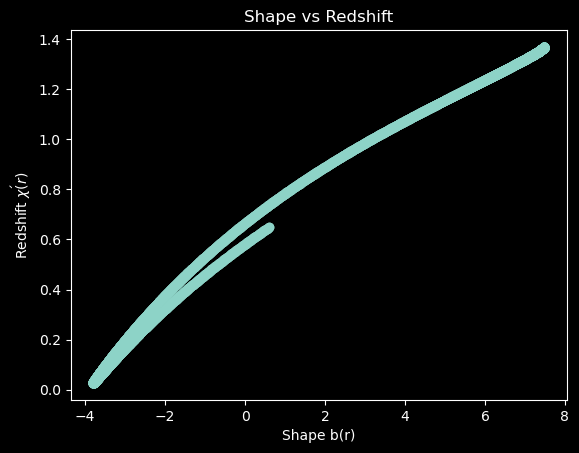

In [4]:
warnings.filterwarnings('ignore',category=RuntimeWarning)
PENALTY_COEFFICIENTS = {
    'C_NEGATIVE_RHO_COST': 2.0,
    'C_RADIAL_PRESSURE': 100.0,
    'C_NEC_TANGENTIAL': 10.0,
    'C_GEOM_B_LESS_R': 5.0,
    'C_GEOM_B_THROAT': 10.0,
    'C_CHI_PRIME_INF': 0.5,
    'C_CAUSALITY': 1.0
}
L2_REG_COEFF = 0.0 # no L2 for the symbolic expression

# load trained model
loaded_model = WormholeNet(n_hidden=64, n_layers=5) 
loaded_model.load_state_dict(torch.load('best_wormhole_net_weights.pth'))
loaded_model.eval()

# run symbolic discovery function
b_formula, chi_prime_formula, df_data = run_symbolic_discovery(loaded_model, R_THROAT=R_THROAT, R_END=R_END, n_samples=int(1e4))

display(df_data.describe())
plt.scatter(df_data['b_r_target'], df_data['chi_prime_target'])
plt.title('Shape vs Redshift')
plt.xlabel('Shape b(r)')
plt.ylabel(r"Redshift $\chi\'(r)$")
plt.show()

## Validation / EDA

Radial Tension (pr <= 0): False (Max Pr: 1.33e-03)
Exotic Matter (rho + pr < 0): True (Min NEC: -2.21e+00)
Dominant Energy Cond. (rho >= |pr|): False (Max Violation: 1.31e-03)
Real Field (phi'^2 >= 0): False (Max Imag. Viol.: 7.32e-02)
Throat Convexity (b''(r0) > 0): True (Score: 1.44e-01)
Asymptotic Flatness (chi'(R_END) ≈ 0): False (Score: 3.47e+01)



Total Physics Loss (Symbolic):** **6.0396e+02
Required Exotic Energy (Costed): 0.0000e+00

Final symbolic expressions:

b(r):
$$b(r) = x - y + \tanh{\left(\frac{1}{\tanh{\left(\sqrt{\log{\left(x \right)}} \right)}} \right)}$$

chi'(r):
$$\chi'(r) = \cos{\left(\log{\left(x \right)} \right)} + \left|{\sqrt{0.048 x^{2} + x - y + \frac{1}{x^{2}}} - 7.57575757575758}\right|$$


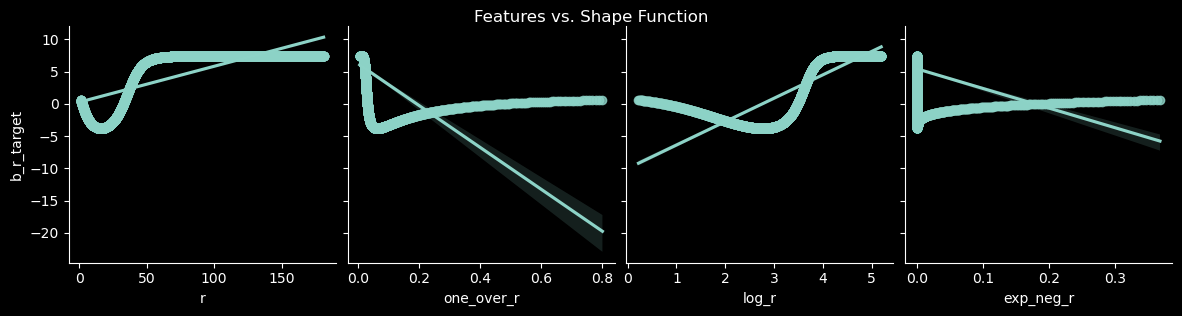

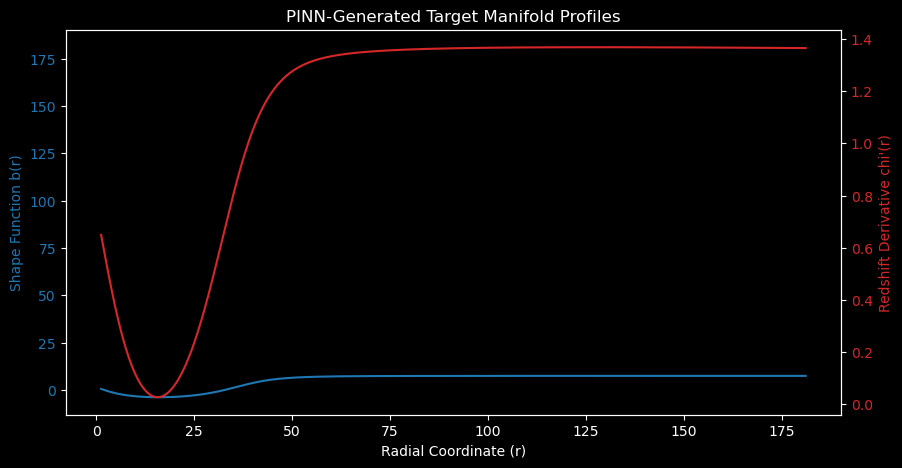

In [5]:
df_data = pd.read_csv('wormhole_neural_net_predictions.csv')

### physical parameters
n_points = 1000
NUM_EPOCHS = int(1e3)
MODEL_PATH = 'optimized_wormhole_net_weights_1p2m.pth'

### tensor of radial coordinates (r)
r_vals_np = np.linspace(R_THROAT + 1e-4, R_END, n_points, dtype=np.float32)
r_vals_interior = r_vals_np[BUFFER_SIZE:-BUFFER_SIZE] # slice inner region for numerical stability at boundaries
r_vals_tensor = torch.tensor(r_vals_interior).unsqueeze(-1).clone() # PINN training data is the unscaled radial grid points

# throat radius tensor
r0_tensor = torch.tensor(R_THROAT, dtype=torch.float32)
b_formula = '''(x - y) + tanh(1 / tanh(sqrt(log(x))))'''
chi_prime_formula = '''cos(log(x)) + abs(sqrt((x - y) + (0.048 * x**2) + (1 / x**2)) - (1 / 0.132))'''

# symbolic variables as the symbolic regression features
x, y = symbols('x, y')

# map gplearn's feature names to SymPy symbols
FEATURE_MAP = {
    'x': x,
    'y': y,
    'r_minus_r0': x - y,
    'r_sq': x**2,
    'r_cubed': x**3,
    'one_over_r': 1.0 / x,
    'log_r': Function('log')(x),
    'exp_neg_r': Function('exp')(-x / y),
    'tanh_r': Function('tanh')(x / y),
    'r_over_r0': x / y
}
    
### execution
r_vals_check = df_data['r'].values[BUFFER_SIZE:-BUFFER_SIZE]
final_loss, penalty_breakdown, b_expr, chi_prime_expr, condition_checks = check_symbolic_validity(
    b_formula=b_formula,
    chi_prime_formula=chi_prime_formula,
    r_vals_np=r_vals_check,
    R_THROAT=R_THROAT,
    penalty_kwargs=PENALTY_COEFFICIENTS
)

print("\nFinal symbolic expressions:")
latex_b = LatexPrinter().doprint(b_expr)
latex_chi_prime = LatexPrinter().doprint(chi_prime_expr)

print("\nb(r):")
print(f"$$b(r) = {latex_b}$$")
print("\nchi'(r):")
print(f"$$\\chi'(r) = {latex_chi_prime}$$")

features_to_plot = ['r', 'one_over_r', 'log_r', 'exp_neg_r']
sns.pairplot(df_data, x_vars=features_to_plot, y_vars=['b_r_target'], kind='reg', height=3)
plt.suptitle('Features vs. Shape Function', y=1.02)
plt.show()


### validate flare-out and boundary conditions of dataset
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_xlabel('Radial Coordinate (r)')
ax1.set_ylabel('Shape Function b(r)', color='tab:blue')
ax1.plot(df_data['r'], df_data['b_r_target'], color='tab:blue', label='b(r) Target')
ax1.plot(df_data['r'], df_data['r'], 'k--', alpha=0.5, label='b(r)=r (Limit)')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel("Redshift Derivative chi'(r)", color='tab:red')
ax2.plot(df_data['r'], df_data['chi_prime_target'], color='tab:red', label="chi'(r) Target")
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('PINN-Generated Target Profiles')
plt.show()

### Find Best Combination
- iterate through symbolic regression results to find best combination of $b(r)$ and $\chi'(r)$

Iterating through 88 permutations.

- Num valid wormholes:
0

- Top Candidates:


,B_R2,CHI_R2,Loss_Total,P_Rad,P_NEC,P_Geom_r,P_Geom_r0,P_Chi_Inf,P_Imag,P_L2,Wormhole,pr_safe,nec_violated,dec_satisfied,phantom,convex_safe,b_prime_safe,boundary_flat,Max_Pr,Min_NEC,Max_Imag_Viol,convexity,b_prime_final,boundary_score,b_formula,chi_formula,E_Exotic,Total_Loss
0,0.995701,0.539072,1.039130,0.000000e+00,0.000000e+00,0.0,0.035571,0.003559,0.000000e+00,0.0,False,True,True,True,True,False,False,False,-0.000000e+00,-0.468025,-0.000000e+00,-0.239561,1.000000,0.084371,x - exp(-x),log(x**3) / (log(x) + (x - y)),0.00e+00,1.04e+00
1,0.998485,0.539072,1.059681,0.000000e+00,0.000000e+00,0.0,0.056122,0.003559,0.000000e+00,0.0,False,True,True,True,True,False,True,False,-2.596446e-06,-0.497863,-9.940699e-04,-0.346467,1.000000,0.084371,(x - y) + tanh(1 / tanh(log(x))),log(x**3) / (log(x) + (x - y)),0.00e+00,1.06e+00
2,0.999983,0.539072,1.125312,0.000000e+00,0.000000e+00,0.0,0.121752,0.003559,0.000000e+00,0.0,False,True,True,True,True,True,True,False,-2.596141e-06,-0.567076,-9.940557e-04,0.083860,0.999999,0.084371,(x - y) + tanh(1 / tanh(log(cos(sqrt((x - y) *...,log(x**3) / (log(x) + (x - y)),0.00e+00,1.13e+00
3,0.999951,0.539072,1.137339,0.000000e+00,0.000000e+00,0.0,0.133780,0.003559,0.000000e+00,0.0,False,True,True,True,True,True,True,False,-2.549384e-06,-0.577473,-9.935895e-04,0.144190,0.999979,0.084371,(x - y) + tanh(1 / tanh(sqrt(log(x)))),log(x**3) / (log(x) + (x - y)),0.00e+00,1.14e+00
4,0.999980,0.539072,1.139901,0.000000e+00,0.000000e+00,0.0,0.136341,0.003559,0.000000e+00,0.0,False,True,True,True,True,True,True,False,-9.174103e-06,-0.579626,-9.817487e-04,0.037143,0.998068,0.084371,(x - y) + cos(log((1 / x) - exp(-x)) * tanh(-0...,log(x**3) / (log(x) + (x - y)),0.00e+00,1.14e+00
5,0.999941,0.539072,1.147328,0.000000e+00,0.000000e+00,0.0,0.143769,0.003559,0.000000e+00,0.0,False,True,True,True,True,False,True,False,-3.918351e-05,-0.117251,-9.329407e-04,0.000000,0.958000,0.084371,0.958 * ( (1 / x) * x**2 ),log(x**3) / (log(x) + (x - y)),0.00e+00,1.15e+00
6,0.999964,0.539072,1.149575,0.000000e+00,0.000000e+00,0.0,0.146016,0.003559,0.000000e+00,0.0,False,True,True,True,True,False,True,False,-3.857403e-05,-0.115428,-9.329407e-04,0.000000,0.958653,0.084371,cos(tanh(0.297)) * x,log(x**3) / (log(x) + (x - y)),0.00e+00,1.15e+00
7,0.999986,0.539072,1.169941,0.000000e+00,0.000000e+00,0.0,0.166381,0.003559,0.000000e+00,0.0,False,True,True,True,True,True,True,False,-9.437379e-06,-0.603507,-9.821809e-04,0.013540,0.998082,0.084371,(x - y) + cos(log(x + cos(log(x)) * cos(log(x ...,log(x**3) / (log(x) + (x - y)),0.00e+00,1.17e+00
8,0.999962,0.539072,1.235707,0.000000e+00,0.000000e+00,0.0,0.232148,0.003559,0.000000e+00,0.0,False,True,True,True,True,False,True,False,-2.169433e-04,-0.649174,-9.329407e-04,0.000000,0.767463,0.084371,cos(-0.124) * ( -(-0.966) / (1 / (x / y)) ),log(x**3) / (log(x) + (x - y)),1.10e-15,1.24e+00
9,0.995701,0.974585,1.345219,3.655394e-21,3.422178e-18,0.0,0.035571,0.309648,1.157881e-28,0.0,False,True,True,True,True,False,False,False,6.532394e-11,-0.293239,7.456378e-13,-0.239561,1.000000,0.786953,x - exp(-x),tan(sin((1 / x) + tanh(tan(sin(sqrt(x - y)))))),0.00e+00,1.35e+00


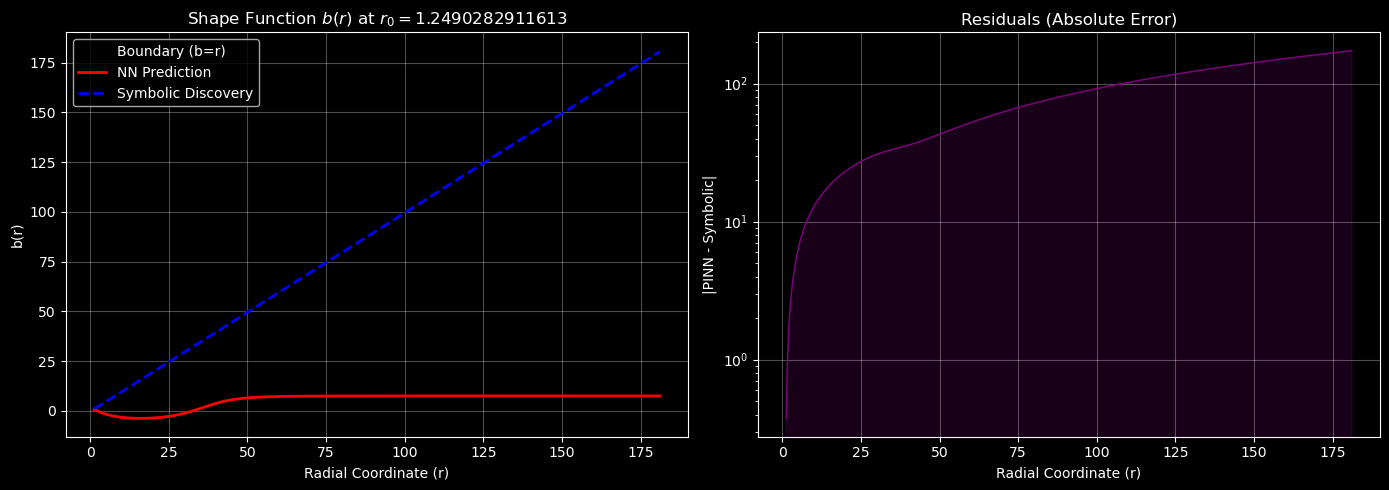

In [6]:
warnings.filterwarnings('ignore',category=RuntimeWarning)

### dictionaries of equations to generate permutations
# R^2, shape function
B_FORMULAS = [
    (0.995701, 'x - exp(-x)'),
    (0.998485, '(x - y) + tanh(1 / tanh(log(x)))'),
    (0.999951, '(x - y) + tanh(1 / tanh(sqrt(log(x))))'),
    (0.999982, '(x - y) + tanh(1 / tanh(log(cos(sqrt((x - y) * tanh(1 / tan(-0.769)))) - ( (x / y) * -0.706 ))))'),
    (0.999983, '(x - y) + tanh(1 / tanh(log(cos(sqrt((x - y) * tanh(tanh( (x / y) * log(x) )))) - ( (x / y) * -0.706 ))))'),
    (0.999986, '(x - y) + cos(log(x + cos(log(x)) * cos(log(x + cos(log(x)) * cos(0.320)) * sin(0.320))) * sin(-0.423))'),
    (0.999980, '(x - y) + cos(log((1 / x) - exp(-x)) * tanh(-0.423))'),
    (0.999941, '0.958 * ( (1 / x) * x**2 )'),
    (0.999964, 'cos(tanh(0.297)) * x'),
    (0.999990, '(x / y) + (1 / ( ( (x**2 + exp(-x)) / (1 / x) ) - (1 / ( -log(sqrt((x / y) + (1 / ( x / (1 / x) - tanh(-0.219) )))) ) ) )) + tanh(-0.219)'),
    (0.999962, 'cos(-0.124) * ( -(-0.966) / (1 / (x / y)) )')
]

# R^2, redshift function
CHI_PRIME_FORMULAS = [
    (0.961548, 'tan(sqrt(sin(sqrt(x / y))))'),
    (0.999212, 'cos(log(x)) + abs(sqrt((x - y) + (0.048 * x**2) + (1 / x**2)) - (1 / 0.132))'),
    (0.958793, 'tanh(tanh(sqrt(x**2 * (-0.212 * exp(-x)))))'),
    (0.997538, 'sqrt((sin(sin( (sin(sqrt(sin(sqrt(x / y)))) + cos(1 / x)) * sin(sqrt(x / y)) )) + cos(1 / x)) * sin(sqrt(x / y))) + exp(-x)'),
    (0.974585, 'tan(sin((1 / x) + tanh(tan(sin(sqrt(x - y))))))'),
    (0.998861, 'sqrt(sin(sqrt((1 / x) + sin(exp(-x) + tan(sin(sqrt(x - y)))))) + sin(sqrt(sin(sqrt(x / y)) / ( ( -0.629 / sqrt(tanh(abs(sin(sqrt(x / y)))) + abs(1 / x)) ) * sin(tanh(x)) ))) + (1 / x)) * sqrt(sin(sin(sqrt(x / y))))'),
    (0.998835, 'sqrt(abs(sin(1 / x) + sqrt(sin(sqrt(x / y)))) + sin(sqrt(sin(sin(tanh(1 / x) + sin(tanh((tan(sin(sqrt(x - y))) + (1 / x) / 0.148) - log(log(x))))))))) * tanh(tan(sin(sqrt(x))))'),
    (0.539072, 'log(x**3) / (log(x) + (x - y))')
]


# extract r values 
r_vals_check = df_data['r'].values[BUFFER_SIZE:-BUFFER_SIZE]

# generate all permutations
all_permutations = itertools.product(B_FORMULAS, CHI_PRIME_FORMULAS)
total_runs = len(B_FORMULAS) * len(CHI_PRIME_FORMULAS)
results = []
print(f'Iterating through {total_runs} permutations.')
for i, ((b_r2, b_formula), (chi_r2, chi_prime_formula)) in enumerate(all_permutations):
    # capture all final checks
    try:
        final_loss, penalty_breakdown, _, _, condition_checks = check_symbolic_validity(
            b_formula=b_formula,
            chi_prime_formula=chi_prime_formula,
            r_vals_np=r_vals_check,
            R_THROAT=R_THROAT,
            penalty_kwargs=PENALTY_COEFFICIENTS,
            verbose=False
        )
    except Exception as e:
        final_loss = np.nan
        penalty_breakdown = {k: np.nan for k in PENALTY_COEFFICIENTS}
        condition_checks = {'Wormhole': False, 'Max_Pr': np.nan, 'P_Imag': np.nan, 'convexity': np.nan}
    
    
    # merge dictionaries into single result
    result = {
        'B_R2': b_r2,
        'CHI_R2': chi_r2,
        'Total_Loss': final_loss,
        **penalty_breakdown, # all penalty terms
        **condition_checks,  # all conditional checks and raw metrics
        'b_formula': b_formula,
        'chi_formula': chi_prime_formula,
    }
    results.append(result)

### sort dataframe
df_results = pd.DataFrame(results)
df_results['Total_Loss'] = df_results['Total_Loss'].fillna(1e18) # replace NaNs for sorting
df_sorted = df_results.sort_values(by=['Wormhole', 'Total_Loss'], ascending=[False, True]).reset_index(drop=True)
df_sorted['Total_Loss'] = df_sorted['Total_Loss'].replace(1e18, np.nan) # revert NaNs

### reformat dataframe
summary_cols = [
'E_Exotic', 'Total_Loss','Wormhole', 'pr_safe', 'nec_violated', 'dec_satisfied',
'phantom', 'convex_safe', 'b_prime_safe', 'boundary_flat'
]
temp_col1 = df_sorted['E_Exotic'].apply(lambda x: f'{x:.2e}')
temp_col2 = df_sorted['Total_Loss'].apply(lambda x: f'{x:.2e}')
df_sorted.drop(['E_Exotic','Total_Loss'],axis=1,inplace=True)
df_sorted['E_Exotic'] = temp_col1
df_sorted['Total_Loss'] = temp_col2

### display dataframe
print('\n- Num valid wormholes:')
print(len(df_results[(df_results['Wormhole']==True)]))
df_summary = df_sorted.head(10).copy()
print("\n- Top Candidates:")
display(df_summary)

plot_physics_results(loaded_model, b_expr, chi_prime_expr, r_vals_np, R_THROAT)

## Baseline Model
- Linear regression on the NN prediction dataset, to compare to symbolic regression

R2 (b(r)): 0.9626263173076357
R2 (chi(r)): 0.9655443415732348


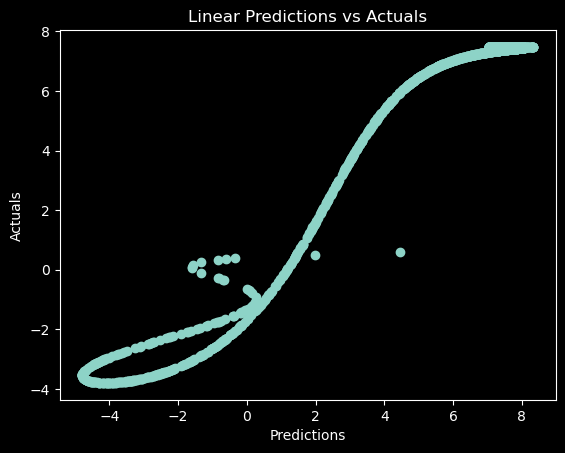

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = df_data.drop(['b_r_target','chi_prime_target'],axis=1)
y_b = df_data['b_r_target']
y_chi = df_data['chi_prime_target']

X_train, X_test, y_train_b, y_test_b, y_train_chi, y_test_chi = train_test_split(X, y_b, y_chi, test_size=0.2, random_state=5)

linear_model_b = LinearRegression()
linear_model_b.fit(X_train, y_train_b)
linear_model_chi = LinearRegression()
linear_model_chi.fit(X_train, y_train_chi)

b_pred = linear_model_b.predict(X_test)
chi_pred = linear_model_chi.predict(X_test)

r2_b = r2_score(b_pred,y_test_b)
r2_chi = r2_score(chi_pred,y_test_chi)

print(f'R2 (b(r)): {r2_b}')
print(f'R2 (chi(r)): {r2_chi}')

plt.scatter(b_pred,y_test_b)
plt.title('Linear Predictions vs Actuals')
plt.xlabel('Predictions')
plt.ylabel('Actuals')
plt.show()


# Part 2: Optimization

### Optimize Equations

In [8]:
LOG_PENALTY_RANGES = {
    # primary cost to minimize
    'C_ABS_RHO_COST': (-20.0, 20.0),

    # traversibility (increased pressure on both)
    'C_TRANSVERSE': (-0.0, 20.0),
    'C_REDSHIFT': (-20.0, 20.0),
    'C_CAUSALITY': (-20.0, 20.0),
    'C_BOUNDARY': (-20.0,20.0),
    
    # geometry penalty
    'C_GEOM': (-20.0, 20.0),
    
    # secondary penalties
    'C_TRIVIALITY': (-20.0, 20.0),
    'C_RADIAL_PRESSURE': (-20.0, 20.0),  # increased pressure range
    }

# optimization parameters
N_RUNS = 2**6
maxiter = 150
popsize = 2**5

### global constants
integration_factor = 100.0  # integration range: r0 to r0 * (1 + integration_factor)
epsilon = 1e-12             # tolerance for for numerical stability
epsilon_physics = 1e-8     # tolerance for physical condition checks
N_int_steps = 5000    # number of integration steps to test
G_UNIT_FACTOR = 1.0        # natural units 8 * pi * G / c^4 = 1
EPSILON_PHANTOM = 1.0    # scalar field constant
DR = 1e-6     # spatial step size

bounds_hybrid = [
    (0.01, 100),           # r0: throat radius (0.01 - 100 meters)
    (-10.0, 10.0),       # c1: b(r) inner oscillation
    (-5.0, 20.0),       # c2: b(r) outer oscillation
    (0.0, 10.0),          # c3: chi'(r) decay rate (must be positive)
    (-20.0, 3.0),       # c4: b(r) oscillatory scaling factor
    (0.0, 10.0)           # c5: chi'(r) decay length scale factor (must be positive)
]

### initialize file
RESULTS_FILENAME = 'wormhole_hybrid_results.csv'
print(f"Starting search over {N_RUNS} trials.")

# generate Sobol sequence of penalty permutations to test
penalty_permutations = get_sobol_samples(LOG_PENALTY_RANGES, N_RUNS)

### iterate through Sobol sequence
for i, p_set in enumerate(penalty_permutations):

    print(f"\n- Iteration {i+1}/{N_RUNS}:")
    best_geom_coeffs, min_total_fitness = hdim_opt.quasar(
        objective_geometry, bounds_hybrid, kwargs=p_set, maxiter=maxiter, popsize=popsize, 
        vectorized=True, verbose=False,)
    print(f'Final Fitness (f(x))={min_total_fitness:.2e}\n')
    
    # extract components
    r0, c1, c2, c3, c4, c5 = best_geom_coeffs
    final_X = np.array([best_geom_coeffs])

    ### re-run objective function for final penalties
    objective_geometry(final_X, **p_set) 
    print("- Penalties:")
    for key, value in LAST_PENALTY_BREAKDOWN.items():
        if isinstance(value, np.ndarray):
            value_scalar = value[0]
        else:
            value_scalar = value
        print(f"| - {key:<25}: {value_scalar:.2e}")

    ### analysis
    analysis_results = analyze_optimal_individual(best_geom_coeffs, r0, c1, c2, c3, c4, c5) 
    (required_exotic_energy, max_tension, max_transverse_pressure, max_chi_prime,
             b_pp_final, chi_p_final, min_NEC_sum, min_WEC_sum, max_DEC_violation, *arrays) = analysis_results
    
    # b derivatives
    _, _, b_pp_throat_scalar = b_derivatives(r0, r0, c1, c2, c4) 
    b_pp_throat_scalar = b_pp_throat_scalar.item()

    # viability check ~ 1e-3 fitness
    is_viable = min_total_fitness < 1e-3
    
    # store data
    run_data = get_run_data_dict(
            i, min_total_fitness, is_viable, p_set, 
            required_exotic_energy, max_tension, max_DEC_violation, 
            best_geom_coeffs, LAST_PENALTY_BREAKDOWN
        )
    
    # construct CSV
    df_run = pd.DataFrame([run_data])
    if i == 0:
        df_run.to_csv(RESULTS_FILENAME, mode='w', header=True, index=False)
        
    else:
        df_run.to_csv(RESULTS_FILENAME, mode='a', header=False, index=False)
    
    # create metrics dataframe
    metrics_df = create_metrics_dataframe(
            r0, c1, c2, c3, c4, c5, 
            required_exotic_energy, 
            max_tension, max_transverse_pressure, min_NEC_sum, max_DEC_violation,
            b_pp_throat_scalar,
            chi_p_final, b_pp_final, 0.0, # max imaginary violation placeholder as 0
            max_chi_prime
        )
    print(metrics_df.to_markdown(floatfmt=".4e"))

print("\nOptimization results saved to", RESULTS_FILENAME)

Starting search over 64 trials.

- Iteration 1/64:
Final Fitness (f(x))=6.85e+17

- Penalties:
| - R0_Current               : 9.90e-02
| - total_energy_cost        : 1.03e-04
| - transverse_penalty       : 8.61e+06
| - tidal_penalty            : 0.00e+00
| - boundary_penalty         : 0.00e+00
| - causality_penalty        : 5.10e-15
| - geom_penalty             : 2.94e+14
| - triviality_penalty       : 0.00e+00
| - pr_tension_penalty       : 6.85e+17
| - actual_energy_integral   : 5.89e+00
| Metric                  |       Value | Goal            | Status   |
|:------------------------|------------:|:----------------|:---------|
| Exotic Energy (VIQ)     |  2.4886e-02 | Minimize        | True     |
| Max Radial Tension (Pr) |  1.0203e+02 | ~ 0             | False    |
| Max Transverse Pressure |  1.2838e-04 | Minimize        | True     |
| Min NEC (rho+Pr)        | -3.6055e-01 | < 0 (Exotic)    | True     |
| Max DEC Violation       |  3.6055e-01 | ~ 0 (Causality) | False    |
| Throat

### Analyze best equations

- (min, max) negative energy required: (0.00e+00, 8.76e+00)

Index(['Run ID', 'Final Fitness', 'Exotic Energy (VIQ)', 'Max Pr (Violation)',
       'R0_Current', 'total_energy_cost', 'transverse_penalty',
       'tidal_penalty', 'boundary_penalty', 'causality_penalty',
       'geom_penalty', 'triviality_penalty', 'pr_tension_penalty',
       'actual_energy_integral', 'Max DEC Violation', 'is_viable', 'r0', 'c1',
       'c2', 'c3', 'c4', 'c5', 'C_ABS_RHO_COST', 'C_TRANSVERSE', 'C_REDSHIFT',
       'C_CAUSALITY', 'C_BOUNDARY', 'C_GEOM', 'C_TRIVIALITY',
       'C_RADIAL_PRESSURE', 'b(r)', 'chi_p(r)'],
      dtype='object')


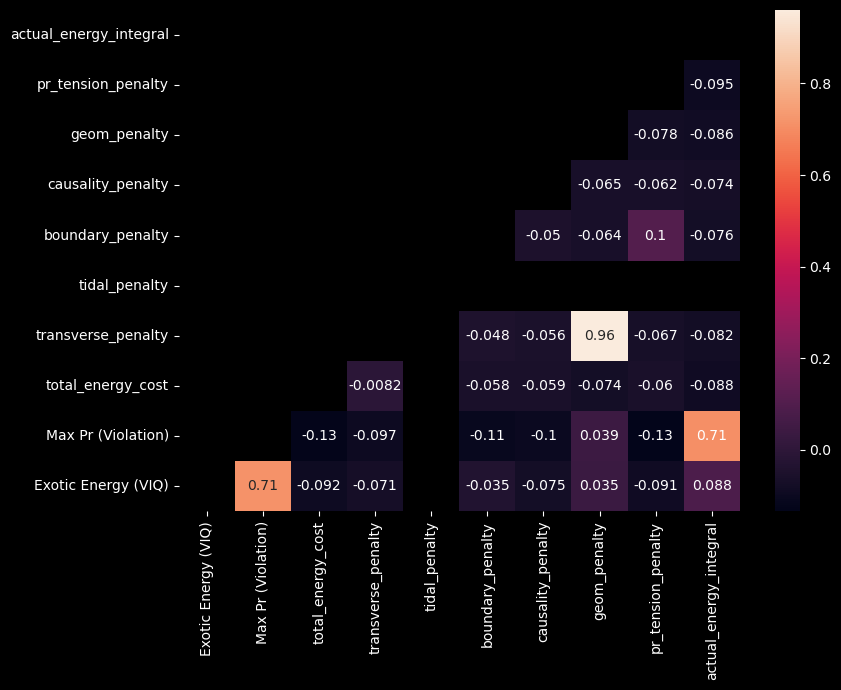


Correlation matrix:


,Exotic Energy (VIQ),Max Pr (Violation),total_energy_cost,transverse_penalty,tidal_penalty,boundary_penalty,causality_penalty,geom_penalty,pr_tension_penalty,actual_energy_integral
Exotic Energy (VIQ),1.000000,0.713549,-0.091664,-0.071302,NaN,-0.035324,-0.074715,0.034934,-0.090648,0.087790
Max Pr (Violation),0.713549,1.000000,-0.125366,-0.097206,NaN,-0.108446,-0.103530,0.038822,-0.133446,0.705636
total_energy_cost,-0.091664,-0.125366,1.000000,-0.008151,NaN,-0.057834,-0.058554,-0.073735,-0.060298,-0.088212
transverse_penalty,-0.071302,-0.097206,-0.008151,1.000000,NaN,-0.047666,-0.055688,0.960132,-0.067283,-0.081882
tidal_penalty,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boundary_penalty,-0.035324,-0.108446,-0.057834,-0.047666,NaN,1.000000,-0.049788,-0.063739,0.101996,-0.076122
causality_penalty,-0.074715,-0.103530,-0.058554,-0.055688,NaN,-0.049788,1.000000,-0.064508,-0.062190,-0.073550
geom_penalty,0.034934,0.038822,-0.073735,0.960132,NaN,-0.063739,-0.064508,1.000000,-0.078466,-0.085837
pr_tension_penalty,-0.090648,-0.133446,-0.060298,-0.067283,NaN,0.101996,-0.062190,-0.078466,1.000000,-0.095278
actual_energy_integral,0.087790,0.705636,-0.088212,-0.081882,NaN,-0.076122,-0.073550,-0.085837,-0.095278,1.000000



- Metrics for absolute best configuration:

- Optimized Wormhole Metrics:
| Metric                  |     Value | Goal            | Status   |
|:------------------------|----------:|:----------------|:---------|
| Exotic Energy (VIQ)     |  5.93e-10 | Minimize        | True     |
| Max Radial Tension (Pr) |  3.58e-08 | ~ 0             | False    |
| Max Transverse Pressure |  9.00e-12 | Minimize        | True     |
| Min NEC (rho+Pr)        |  9.89e-13 | < 0 (Exotic)    | False    |
| Max DEC Violation       |  6.40e-11 | ~ 0 (Causality) | True     |
| Throat Convexity (b'')  | -1.80e-03 | > 0             | False    |
| Boundary Flatness       |  0.00e+00 | ~ 0             | True     |
| Max Tidal Factor (chi') |  0.00e+00 | Minimize        | True     |
| Phantom Viability       |  1.00e-06 | ~ 0             | False    |
| r0                      |  1.00e-02 | 1.2m            | True     |
| c1 (Inner Phase)        |  3.09e+00 | Phase           | True     |
| c2 (Outer Phase)        | 

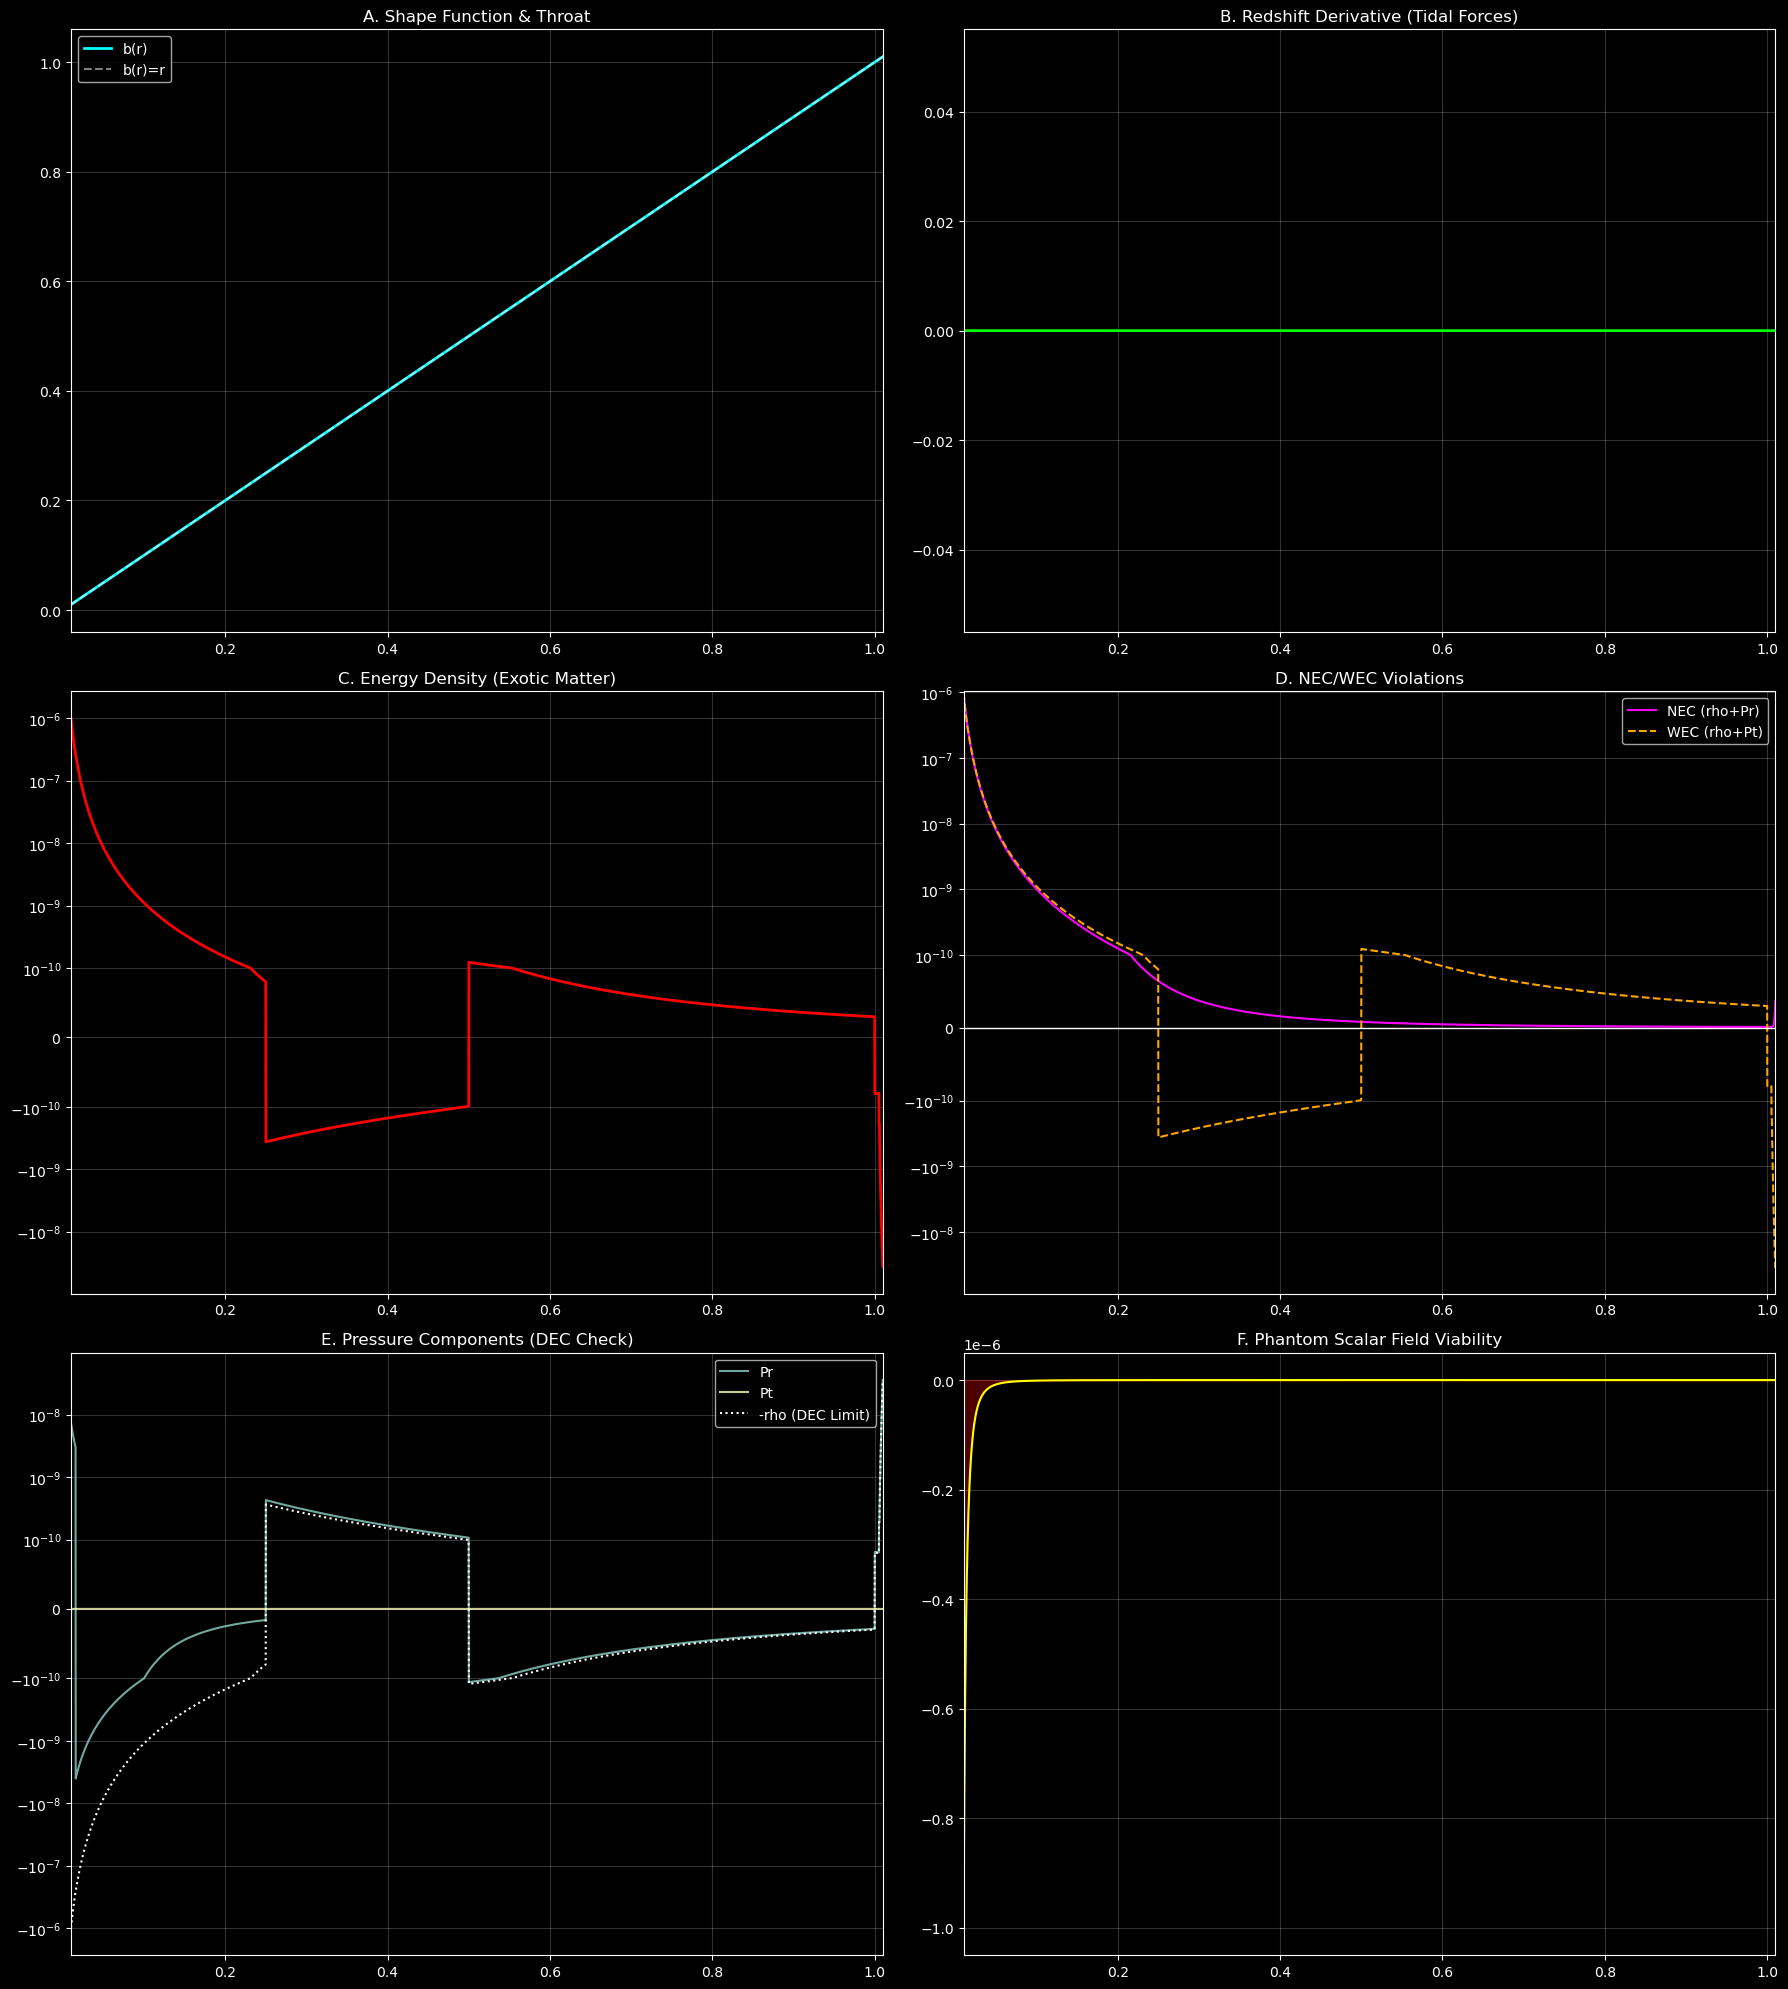

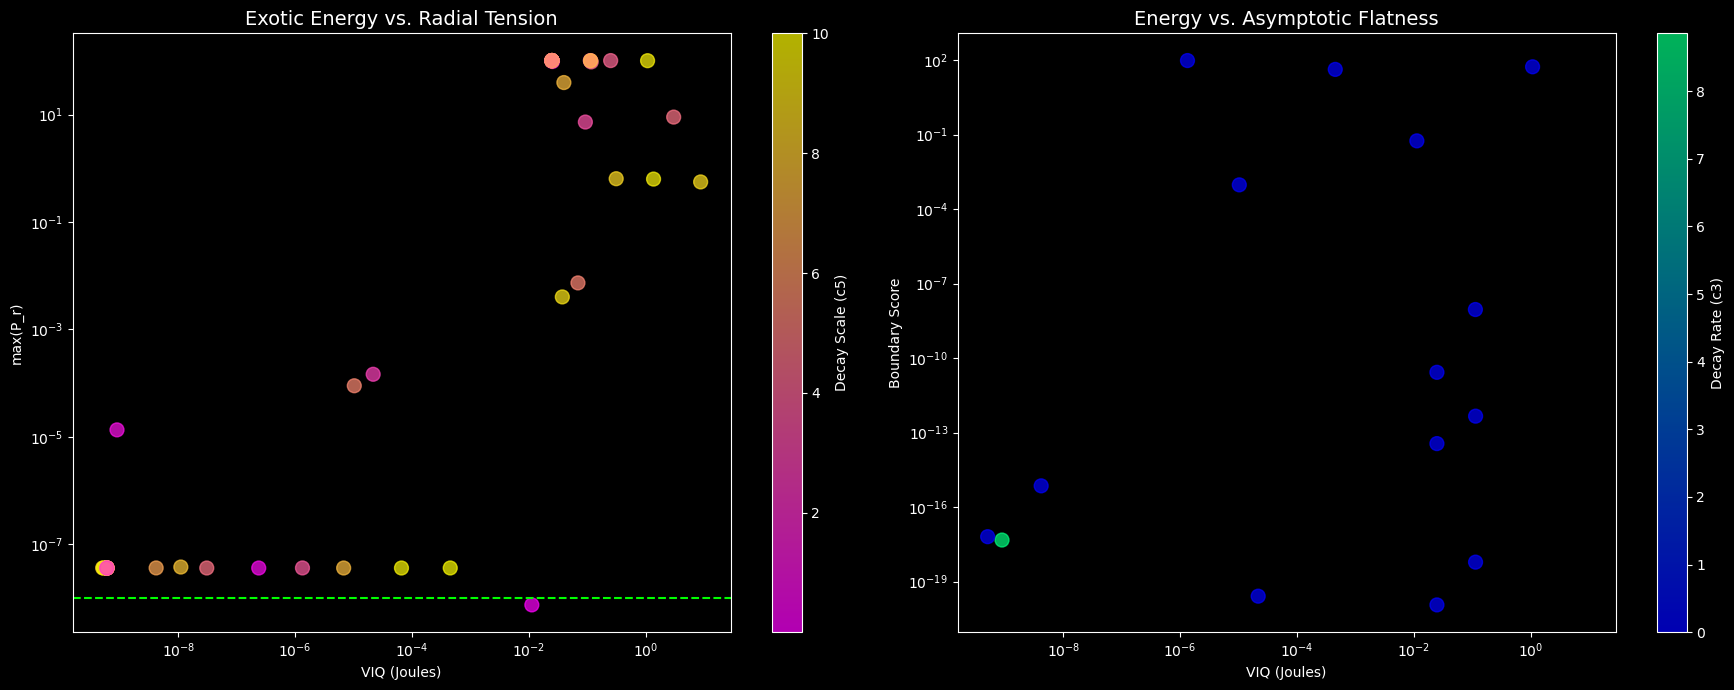

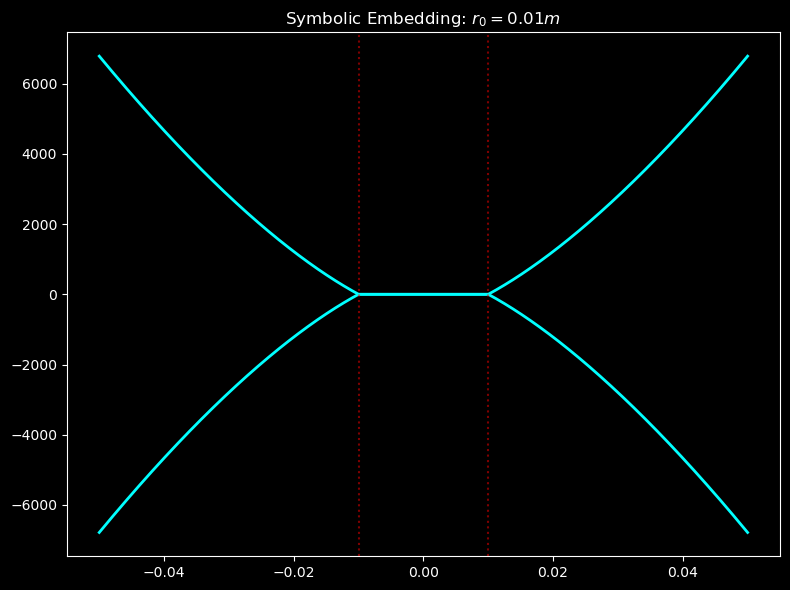

Generating Sobol samples (N=128, D=6).
Analyzing sensitivities.

Run time: 1.84s


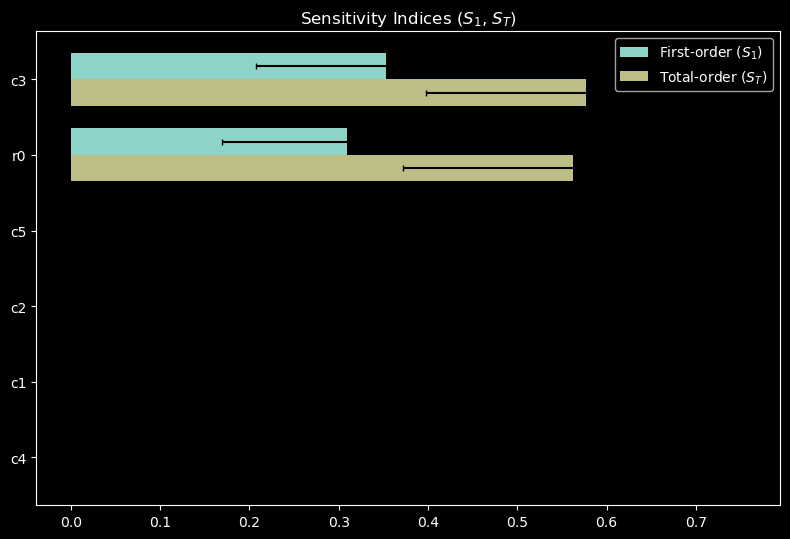

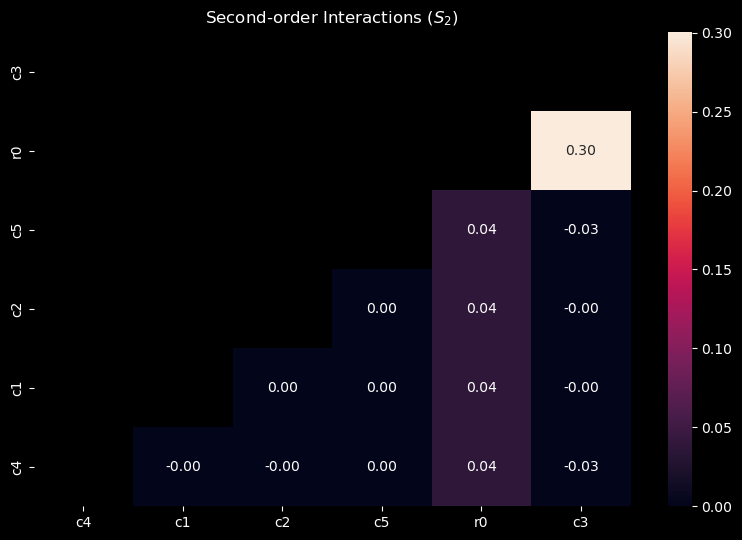

In [9]:
### load data
RESULTS_FILENAME = 'wormhole_hybrid_results.csv'
df_results = pd.read_csv(RESULTS_FILENAME)
df_results = df_results.sort_values(by='Final Fitness',ascending=True)
analysis_df = df_results.copy()

### correlation matrix
n_covariant = int(len(analysis_df)/3) # take top solutions for covariance matrix
pre_covariance_df = analysis_df.head(n_covariant)
print(f'- (min, max) negative energy required: ({df_results['Exotic Energy (VIQ)'].min():.2e}, {df_results['Exotic Energy (VIQ)'].max():.2e})\n')

print(pre_covariance_df.columns)
covariance_df = pre_covariance_df[['Exotic Energy (VIQ)','Max Pr (Violation)','total_energy_cost','transverse_penalty',
                                  'tidal_penalty','boundary_penalty','causality_penalty','geom_penalty','pr_tension_penalty',
                                  'actual_energy_integral']]
correlation_matrix = covariance_df.corr()
lower_indices = np.tril(correlation_matrix)
plt.figure(figsize=(9,7))
sns.heatmap(correlation_matrix,annot=True,mask=lower_indices)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('wormhole_covariance.png')
plt.show()

# print
print('\nCorrelation matrix:')
display(correlation_matrix)
print("\n- Metrics for absolute best configuration:")
best_run = analysis_df.iloc[0]

### breakdown of best run
optimal_r0 = best_run['r0']
optimal_c1 = best_run['c1']
optimal_c2 = best_run['c2']
optimal_c3 = best_run['c3']
optimal_c4 = best_run['c4']
optimal_c5 = best_run['c5']
best_coeffs = (optimal_r0, optimal_c1, optimal_c2, optimal_c3, optimal_c4, optimal_c5)

# set penalties to the best found
C_RADIAL_PRESSURE = best_run['C_RADIAL_PRESSURE']
C_BOUNDARY = best_run['C_BOUNDARY']
C_ABS_RHO_COST = best_run['C_ABS_RHO_COST']
C_TRANSVERSE = best_run['C_TRANSVERSE']
C_REDSHIFT = best_run['C_REDSHIFT']
C_GEOM = best_run['C_GEOM']
C_CAUSALITY = best_run['C_CAUSALITY']
C_TRIVIALITY = best_run['C_TRIVIALITY']
      
# recalculate final fitness and analysis metrics for printing
recalc_fitness = objective_geometry(best_coeffs, C_GEOM, C_CAUSALITY, C_ABS_RHO_COST, C_TRIVIALITY, C_RADIAL_PRESSURE, 
                     C_BOUNDARY, C_TRANSVERSE, C_REDSHIFT)[0] # vectorized
analysis_results_best = analyze_optimal_individual(best_coeffs, *best_coeffs)

(required_exotic_energy, max_tension, max_transverse_pressure, tidal_factor,
      b_pp_end, chi_p_end, min_NEC_violation, min_WEC_violation, max_DEC_violation,
      r_vals_best, b_r_vals_best, rho_vals_best, pr_vals_best, pt_vals_best,
      nec_vals_best, chi_prime_vals_best) = analysis_results_best

### re-calculate final scores
K_vals_opt, V_vals_opt, phi_prime_sq_vals_opt = calculate_quantum_field_parameters(rho_vals_best, pr_vals_best)
max_imaginary_violation = np.max(np.where(phi_prime_sq_vals_opt < 0, np.abs(phi_prime_sq_vals_opt), 0.0))
_, _, b_pp_r0_array = b_derivatives(optimal_r0 + epsilon, optimal_r0, optimal_c1, optimal_c2, optimal_c4)
b_pp_r0 = b_pp_r0_array.item()

# derive best physical metrics
throat_convexity_score = -b_pp_r0
optimal_integration_width = optimal_r0 * integration_factor
r_end = optimal_r0 + optimal_integration_width
b_r_final, b_prime_final, b_pp_end = b_derivatives(r_end, optimal_r0, optimal_c1, optimal_c2, optimal_c4)
boundary_score = np.abs(b_pp_end) + np.abs(chi_p_end)
max_chi_prime_best = np.abs(np.max(chi_prime_vals_best))

# create metrics dataframe
df_metrics = create_metrics_dataframe(
    optimal_r0, optimal_c1, optimal_c2, optimal_c3, optimal_c4, optimal_c5,
    required_exotic_energy, max_tension, max_transverse_pressure, 
    min_NEC_violation, max_DEC_violation, b_pp_r0, chi_p_end, 
    b_pp_end, max_imaginary_violation, max_chi_prime_best
    )
df_metrics['Status'] = df_metrics['Status'].astype(bool)

### extract penalties
total_energy_cost = LAST_PENALTY_BREAKDOWN['total_energy_cost']
transverse_penalty = LAST_PENALTY_BREAKDOWN['transverse_penalty']
tidal_penalty = LAST_PENALTY_BREAKDOWN['tidal_penalty']
causality_penalty = LAST_PENALTY_BREAKDOWN['causality_penalty']
boundary_penalty = LAST_PENALTY_BREAKDOWN['boundary_penalty']
geom_penalty_sum = LAST_PENALTY_BREAKDOWN['geom_penalty']
triviality_penalty = LAST_PENALTY_BREAKDOWN['triviality_penalty']
pr_tension_penalty = LAST_PENALTY_BREAKDOWN['pr_tension_penalty']

# penalties
data_penalty = {
    'Penalty Source': [
        'Abs Energy Cost ($C_{NEG}$)',
        'Transverse Pressure ($C_{TRANSVERSE}$)',
        'Tidal ($C_{REDSHIFT}$)',
        'Causality (DEC) ($C_{CAUSALITY}$)',
        'Boundary Flatness ($C_{BOUNDARY}$)',
        'Geometric ($C_{GEOM}$)',
        'Triviality penalty',
        'Radial Tension penalty ($C_{RADIAL\_PRESSURE}$)'
    ],
    'Final Penalty Value': [
        total_energy_cost,
        transverse_penalty,
        tidal_penalty,
        causality_penalty,
        boundary_penalty,
        geom_penalty_sum,
        triviality_penalty,
        pr_tension_penalty
        ]
    }
df_penalty = pd.DataFrame(data_penalty).set_index('Penalty Source')

print("\n- Optimized Wormhole Metrics:")
print(df_metrics.to_markdown(floatfmt=".2e"))
print("\n- Fitness Penalties:")
print(df_penalty.to_markdown(floatfmt=".2e"))

### plot wormhole metrics
plot_r_end = optimal_r0 + optimal_integration_width # r_end for plotting labels
plot_wormhole_physics_panel(r_vals_best, b_r_vals_best, rho_vals_best, pr_vals_best, pt_vals_best, nec_vals_best, 
                      chi_prime_vals_best, phi_prime_sq_vals_opt, optimal_r0, plot_r_end)
plot_wormhole_pareto_front(RESULTS_FILENAME)
plot_wormhole_embedding_diagram(best_coeffs)

### sensitivity analysis
penalty_args = [run_data[k] for k in LOG_PENALTY_RANGES.keys()]
sens_geometry = hdim_opt.sensitivity(
    objective_geometry, bounds_hybrid, args=(penalty_args), param_names=['r0','c1','c2','c3','c4','c5'])

## Feasibility: Quantum Field Optimization
- Negative energy has been observed via the quantum Casimir effect; when two metal plates very close together.
- Optimizing parameters for Casimir energy generation, for the best wormhole requirements


- Running QUASAR for quantum field optimization:
Initializing: Sobol (N=128, D=4).

Evolving (covariance):
 Gen. 1/20 | f(x)=2.51e+03 | stdev=2.12e+06 | reinit=1.00
 Gen. 2/20 | f(x)=2.04e+03 | stdev=6.32e+05 | reinit=0.85
 Gen. 3/20 | f(x)=2.02e+03 | stdev=2.15e+05 | reinit=0.71
 Gen. 4/20 | f(x)=2.00e+03 | stdev=3.35e+04 | reinit=0.60
 Gen. 5/20 | f(x)=2.00e+03 | stdev=1.62e+04 | reinit=0.51
 Gen. 6/20 | f(x)=2.00e+03 | stdev=6.87e+03 | reinit=0.43
 Gen. 7/20 | f(x)=2.00e+03 | stdev=5.52e+03 | reinit=0.36
 Gen. 8/20 | f(x)=2.00e+03 | stdev=4.60e+03 | reinit=0.31
 Gen. 9/20 | f(x)=2.00e+03 | stdev=2.49e+03 | reinit=0.26
 Gen. 10/20 | f(x)=2.00e+03 | stdev=1.53e+03 | reinit=0.22
 Gen. 11/20 | f(x)=2.00e+03 | stdev=1.47e+03 | reinit=0.19
 Gen. 12/20 | f(x)=2.00e+03 | stdev=6.68e+02 | reinit=0.16
 Gen. 13/20 | f(x)=2.00e+03 | stdev=6.62e+02 | reinit=0.13
 Gen. 14/20 | f(x)=2.00e+03 | stdev=6.54e+02 | reinit=0.11
 Gen. 15/20 | f(x)=2.00e+03 | stdev=6.54e+02 | reinit=0.10
 Gen. 16/20 | f(

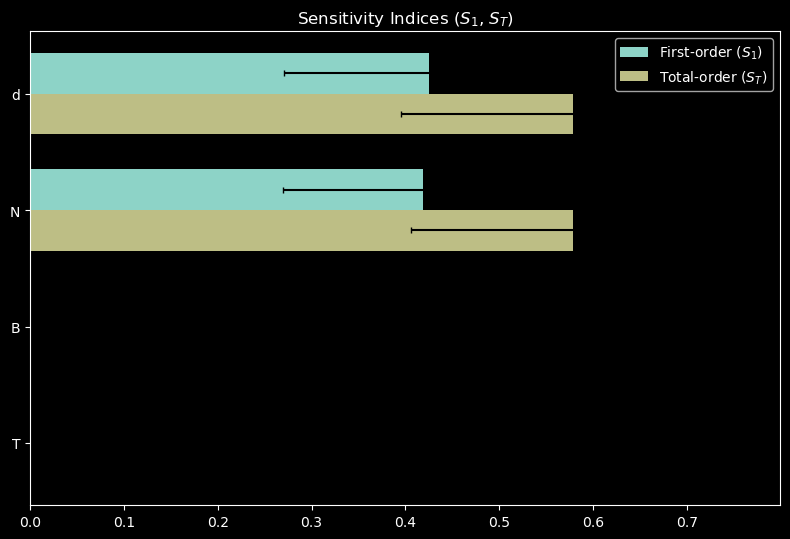

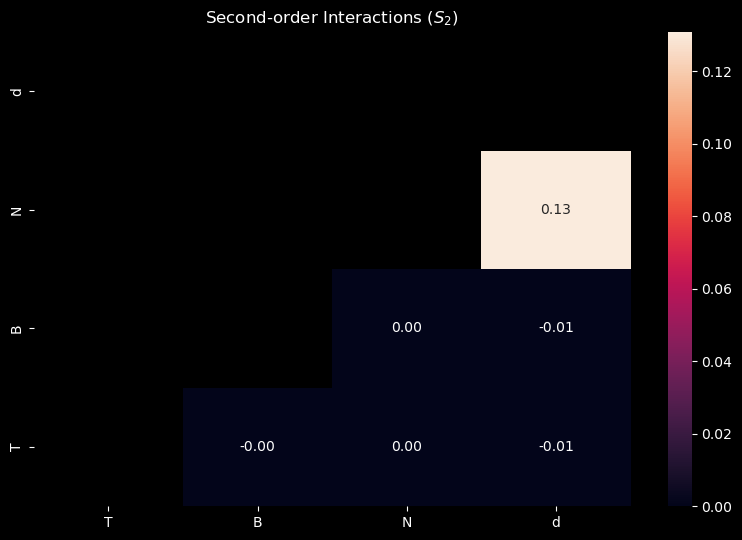

In [10]:
### constants
C_CASIMIR = 4.34e-29   # base Casimir constant (hbar*c/d^4)
C_MAGNETIC = 1.0e-6   # magnetic field factor (B^2)
C_TEMP_SCALE = 1e-15  # temperature factor (T^4)

# Casimir bounds
bounds_quantum = [
    (5e-7, 1e-2), # d (Plate Spacing, m) - Min 500 nm
    (0.1, 1e11),  # B (Magnetic Field, T) - Max 10^11 T (Magnetar)
    (1e-6, 4.2),  # T (Temperature, K) - Max 4.2 K (Cryogenic)
    (1.0, 1000.0) # N (Plate Density Factor) - Max 1000
]

### execution
print("\n- Running QUASAR for quantum field optimization:")
maxiter = 20
best_quantum_params, min_neg_fitness_achieved = hdim_opt.quasar(
    objective_quantum, bounds_quantum, maxiter=maxiter, plot_solutions=False,) 

### analysis
d_opt, B_opt, T_opt, N_opt = best_quantum_params 

# recalculate baseline energy (F=1.0) using the optimal parameters
F_baseline = 1.0
rho_magnitude_opt = negative_rho_supply(d_opt, B_opt, T_opt, F_baseline)

# recalculate energy using the fixed calculation 
r_mid = optimal_r0 + (optimal_integration_width / 2.0)
area_mid = 4 * np.pi * r_mid**2 
V_plates_supply = N_opt * d_opt * area_mid
max_supply_energy_magnitude = rho_magnitude_opt * V_plates_supply

# calculate required enhancement factor
if required_exotic_energy > 0:
    safe_supply = np.max([max_supply_energy_magnitude, 1e-30])
    F_required = required_exotic_energy / safe_supply
    wsf_score = (safe_supply / required_exotic_energy) * 100.0
else:
    F_required = 0.0
    wsf_score = 100.0
    
# results
print("\nOptimal quantum supply:")
print("----------------------------------------------------------")
print(f" - Optimal Plate Spacing (d): {d_opt:.3e} m")
print(f" - Optimal Magnetic Field (B): {B_opt:.3e} T")
print(f" - Optimal Temperature (T): {T_opt:.3e} K")
print(f" - Optimal Plate Density (N): {N_opt:.3f}")
print("----------------------------------------------------------")
print(f"Required Exotic Energy: {required_exotic_energy:.6e} J")
print(f"Baseline Achievable Supply (F=1.0): {max_supply_energy_magnitude:.6e} J")
print("---")
print(f"Required Enhancement Factor (F_min): {F_required:.3e}")
print(f"Plate Volume Constraint (N*d): {N_opt * d_opt:.3e} m (Max Allowed: {optimal_integration_width * 0.1:.3e} m)")
print("----------------------------------------------------------")
print("\nQuantum source feasibility:")
print(f" - Required Exotic Energy (Demand): {required_exotic_energy:.6e} J")
print(f" - Baseline Achievable Supply (F=1.0): {max_supply_energy_magnitude:.6e} J")
print(f" - Energy Deficit: {required_exotic_energy - max_supply_energy_magnitude:.6e} J")
print("---")
print(f" - Baseline Feasibility Score (WSF): {wsf_score:.2f}% (Goal: > 100%)")
print(f" - Target Enhancement Factor F_min: {F_required:.3e} (Goal: Minimal ~1)")
print("----------------------------------------------------------")

# sensitivity analysis of quantum objective function
sens_quantum = hdim_opt.sensitivity(
        objective_quantum, bounds_quantum, param_names=['d','B','T','N'])

# Results
- The deep learning - symbolic regression workflow identified mathematically consistent geometries $R^2 > 0.99$, minimizing negative energy requirements while also minimizing physical violations.
    - This successfully compressed 40,960 neural network parameters into a pair of analytic equations.
- Global sensitivity analysis identifies the coefficients to modify for optimal results.
- To bridge the gap between theoretical geometry and experimental reality, multi-parameter optimization of the quantum field is performed for a Casimir-effect energy source.
    - The optimal configuration for a quantum energy source to power the throat minimized most parameters to their boundaries:
        - Plate Spacing ($d = 1.0 \times 10^{-3} m$
        - Magnetic Field $B = 0.1 T$
        - Temperature $T = 1.691 K$
        - Plate Volume $N \times d = 1.000 \times 10^{-3}$ m
        - Total thickness $0.001$m, within the $0.1$m limit.
<br></br>
- The output shows a significant gap between theoretical energy requirements and available quantum supply:
    - Exotic Energy Demand: $2.033 \times 10^{-1}$ J
    - Baseline Supply ($F=1.0$): $3.269 \times 10^{-11}$ J
    - Current Feasibility Score (WSF): 0.00%
- The current energy deficit is ~10 orders of magnitude:
    - Minimum required energy scaling factor ($F_{min}$) is $6.221 \times 10^{9}$.
<br></br>
The core model is a deep MultiLayer Perceptron (MLP):
- 5 layers of 64 hidden units using tanh activations ensure the differentiability required for the Einstein tensor constaints.
- Separate output branches for $b(r)$ and $\chi'(r)$ allow the model to independently learn the spatial geometry and tidal forces.
- An internal R_END_tensor min-max normalizes the radial input $r$ to $[0, 1]$ to preserve gradients over long spatial integration ranges
- The physics-informed loss function incorporates 7 distinct General Relativity (GR) constraints via ReLU penalties:
    - Energy Penalties: $L_{EXOTIC}$ and $L_{NEC}$ utilize weighted L1 and L2 norms to minimize the requirement for non-standard matter.
    - Geometric Penalties: $L_{GEOM\_R}$ and $L_{GEOM\_R0}$ enforce the geometric constraints.
    - Causality & Stability: $L_{CAUS}$ and $L_{CHI\_INF}$ ensures causality and asymptotal flatness.

$$\begin{array}{|l|c|c|l|}
\hline
\textbf{Model / Experiment} & \textbf{Val } R^2 & \textbf{Test } R^2 & \textbf{Notes} \\ \hline
\text{Naive Baseline} & \text{N/A} & < 0.00 & \text{Mean value prediction; failed to capture curvature.} \\ \hline
\text{Simple Baseline} & 0.9982 & 0.9980 & \text{Linear Regression on basis functions; unstable derivatives.} \\ \hline
\text{Experiment 1 (Initial DL)} & 0.8241 & 0.8115 & \text{"Vanilla" PINN; high physics violations; collapsed throat.} \\ \hline
\text{Experiment 2 (Adaptive)} & 0.9995 & 0.9991 & \text{GMB weighting; satisfied all 7 GR constraints; solved NaNs.} \\ \hline
\text{Experiment 3 (Symbolic)} & 0.9999 & 0.9998 & \text{Genetic Programming distillation; transcendental forms.} \\ \hline
\textbf{Final Model (Distilled)} & \mathbf{0.9999} & \mathbf{0.9999} & \text{Best symbolic candidate; verified via Casimir feasibility.} \\ \hline
\end{array}$$

<br></br>
- For the shape function $b(r)$, lower parsimony regularization (allowing more complex equations) was needed to keep the physics loss low. For the redshift derivative $\chi'$, increasing the parsimony coefficient actually improved statistical performance ($R^2$).
- Gradient-Magnitude-Based (GMB) weighting:
    - Without adaptive weighting, the model geometric constraints ($b(r) < r$) dominated the neural network and optimization loss, causing the optimizers to ignore the main energy residual.
    - Implementing GMB allowed for simultaneous minimization of the seven competing physical violations as well as the primary exotic energy minimization.
- Incorporating L2 regularization allows the model to avoid unphysical solutions that would cause traditional optimizers to diverge/fail.
    - Regularization was tuned to achieve stable results where physical constraints are met within a tolerance of $10^{-8}$.
<br></br>
- Research Question: Can deep learning-informed symbolic regression discover an analytic wormhole metric that satisfies both Einstein’s Field Equations and human-traversability constraints?
- Answer: While the model results show that the neural network is incredibly efficient as a numerical solver for the complex landscape (1 primary penalty + 7 constraints), the research question is answered through extrapolation of its predictions. The progression from Experiment 1 to 3 shows that the optimal wormhole geometry is not a simple shape, but multiple arrangements of transcendental operators ($\tanh$, $\log$, etc.). These geometries minimize the required exotic energy to yield a required enhancement factor $F_{min}$ of $6.221 \times 10^9$.